#John Clark | 8500

In [ ]:
#1 Setup and reproducibility
import os, time, warnings
import numpy as np, pandas as pd, polars as pl          # polars reads the big gz files fast
import matplotlib.pyplot as plt, seaborn as sns
from scipy import optimize, stats                       # optimize: fit hoop location; stats: KS test
from sklearn.ensemble import HistGradientBoostingClassifier   # fast GBM that handles NaN natively
from sklearn.model_selection import KFold, StratifiedKFold, GroupKFold
from sklearn.metrics import log_loss, roc_auc_score

warnings.filterwarnings("ignore")        # keep the notebook output readable
SEED = 42                                # single source of randomness for the whole notebook
rng = np.random.default_rng(SEED)        # numpy generator used for permutation baselines
os.makedirs("figures", exist_ok=True)    # every chart is saved here for the write-up
sns.set_theme(style="whitegrid")

CHANGELOG = []                           # list of dicts; turned into a table at the end
def log_change(step, column, n_rows, action):
    """Record one data modification: which step, which column, how many rows, what was done."""
    CHANGELOG.append(dict(step=step, column=column, rows_affected=int(n_rows), action=action))

def savefig(name):
    """Tidy layout, save the current figure to figures/<name>.png, then display it."""
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

# Columns that must be read as TEXT. IDs are hashes like "8f2113635e"; if a hash happened to
# look like a number (e.g. "12e4567890" = scientific notation) a naive reader would corrupt it.
STR_COLS = ["season_id", "off_team_id", "def_team_id", "shooter_id", "closestdef_id",
            "contester1_id", "contester2_id", "contester3_id", "contester4_id",
            "month", "gamestate", "shottype", "closestdefapproach"]

In [ ]:
#2 Raw missing-value inspection
raw_tr = pl.read_csv("training.csv.gz", infer_schema_length=0)   # infer_schema_length=0 => all Utf8 (strings)
raw_te = pl.read_csv("testing.csv.gz",  infer_schema_length=0)
print("raw shapes:", raw_tr.shape, raw_te.shape)

# Candidate placeholder tokens. Add more here if you spot others in the data.
TOKENS = ["", "NA", "N/A", "NaN", "nan", "null", "NULL", "None", "?", "-", "-1", "-999", "999", "9999"]

rows = []
for split, df in [("train", raw_tr), ("test", raw_te)]:
    for c in df.columns:
        s = df[c]
        for tok in TOKENS:
            n = int((s == tok).sum())                 # exact-string matches of this token
            if n:                                     # only record tokens that actually occur
                rows.append(dict(split=split, column=c, token=repr(tok), n=n,
                                 pct=round(100 * n / len(df), 3)))
        n_null = int(s.null_count())                  # true nulls (empty fields the reader already recognized)
        if n_null:
            rows.append(dict(split=split, column=c, token="<true null>", n=n_null,
                             pct=round(100 * n_null / len(df), 3)))

sentinels = pd.DataFrame(rows)
sentinels.sort_values(["column", "split"]).reset_index(drop=True)

raw shapes: (425719, 29) (213977, 28)


,split,column,token,n,pct
0,test,contester1_id,'NA',24086,11.256
1,train,contester1_id,'NA',46007,10.807
2,test,contester2_id,'NA',180408,84.312
3,train,contester2_id,'NA',356016,83.627
4,test,contester3_id,'NA',212121,99.133
5,train,contester3_id,'NA',421653,99.045
6,test,contester4_id,'NA',213964,99.994
7,train,contester4_id,'NA',425682,99.991
8,test,distcont1,'NA',24086,11.256
9,train,distcont1,'NA',46007,10.807


In [ ]:
#3 Typed data loading
STR_OVERRIDES = {c: pl.String for c in STR_COLS}    #force these columns to text

def load(path):
    """Read a csv.gz into pandas: 'NA' -> missing, ID columns stay as text."""
    return pl.read_csv(path, null_values=["NA"], schema_overrides=STR_OVERRIDES,
                       infer_schema_length=100_000).to_pandas()

train = load("training.csv.gz")
test  = load("testing.csv.gz")
sub   = pd.read_csv("submission.csv")               #template: columns shot_id, make_prob
print(train.shape, test.shape, sub.shape)
train.dtypes                                        

(425719, 29) (213977, 28) (213977, 2)


shot_id                 int64
outcome                  bool
season_id              object
off_team_id            object
def_team_id            object
shooter_id             object
closestdef_id          object
num_contesters          int64
contester1_id          object
contester2_id          object
contester3_id          object
contester4_id          object
distcont1             float64
distcont2             float64
distcont3             float64
distcont4             float64
contested                bool
month                  object
gamestate              object
shottype               object
distance              float64
locationx             float64
locationy             float64
three                    bool
dribblesbefore          int64
shotclock             float64
closestdefdist        float64
closestdefapproach     object
shooterspeed          float64
dtype: object

In [ ]:
#4 Feature-definition reference
dd = pd.DataFrame([
    ("shot_id",                "unique shot identifier",                                   "-"),
    ("outcome",                "1 = made, 0 = missed",                                     "-"),
    ("distance",               "distance from basket",                                     "feet"),
    ("locationx / locationy",  "court coordinates",                                        "feet"),
    ("shotclock",              "seconds remaining on the shot clock",                      "seconds"),
    ("closestdefdist",         "closest defender distance at release",                     "feet"),
    ("closestdefapproach",     "defender distance at 1.00, 0.75, 0.50, 0.25 s before shot", "feet"),
    ("distcont1-4",            "contester distances",                                      "feet"),
    ("shooterspeed",           "shooter speed at release",                                 "ft/s"),
    ("three",                  "was a 3-point attempt",                                    "bool"),
    ("num_contesters / contested", "number of contesters / any contester",                 "-"),
], columns=["column", "stated meaning (from brief)", "stated unit"])
dd["verified by me?"] = ""       
dd

verified = {
    "distance":              "YES: equals hypot(x - hoop_x, y - hoop_y) with residual 0.000 ft; hoop fit at (-41.75, 0). It is DERIVED from the coordinates, not independent.",
    "locationx / locationy": "YES: one basket for all shots; x runs from about -47 (baseline) to +47. A few shots (about 0.02%) lie slightly outside the court.",
    "closestdefapproach":    "YES: 4 numeric values in every row; order is oldest -> newest (gap to closestdefdist shrinks 4.4 -> 1.1 ft, correlation rises 0.62 -> 0.94).",
    "distcont1-4":           "YES: missing exactly when the contester does not exist (0 exceptions in train and test).",
    "three":                 "YES: 0% flagged at <=22 ft, ~93% at 22-23.75 ft, 100% beyond.",
    "num_contesters / contested": "YES: contested == (num_contesters > 0) in every row.",
    "shotclock":             "PARTLY: range 0-24 confirmed, but 2.4% of shots sit at exactly 24.00 (putbacks) and 2.3% at exactly 0.00 (expired/off clock). Treated as real regimes, not missing.",
}
dd["verified by me?"] = dd["column"].map(verified).fillna("")
dd

,column,stated meaning (from brief),stated unit,verified by me?
0,shot_id,unique shot identifier,-,
1,outcome,"1 = made, 0 = missed",-,
2,distance,distance from basket,feet,"YES: equals hypot(x - hoop_x, y - hoop_y) with..."
3,locationx / locationy,court coordinates,feet,YES: one basket for all shots; x runs from abo...
4,shotclock,seconds remaining on the shot clock,seconds,"PARTLY: range 0-24 confirmed, but 2.4% of shot..."
5,closestdefdist,closest defender distance at release,feet,
6,closestdefapproach,"defender distance at 1.00, 0.75, 0.50, 0.25 s ...",feet,YES: 4 numeric values in every row; order is o...
7,distcont1-4,contester distances,feet,YES: missing exactly when the contester does n...
8,shooterspeed,shooter speed at release,ft/s,
9,three,was a 3-point attempt,bool,"YES: 0% flagged at <=22 ft, ~93% at 22-23.75 f..."


In [ ]:
#5 Dataset integrity checks
checks = {}
checks["train rows == 425,719 (brief)"]         = len(train) == 425_719
checks["test rows == 213,977 (brief)"]          = len(test) == 213_977
checks["train shot_id unique"]                  = train.shot_id.is_unique
checks["test shot_id unique"]                   = test.shot_id.is_unique
checks["no shot_id shared by train and test"]   = len(set(train.shot_id) & set(test.shot_id)) == 0
#Duplicate rows are compared EXCLUDING shot_id, because shot_id is unique by construction.
checks["exact duplicate rows in train"]         = int(train.drop(columns="shot_id").duplicated().sum())
checks["exact duplicate rows in test"]          = int(test.drop(columns="shot_id").duplicated().sum())
# Test must have the same columns as train, in the same order, minus the outcome.
checks["test cols == train cols minus outcome"] = list(test.columns) == [c for c in train.columns if c != "outcome"]
#Submission ids must match test ids AND order (the brief forbids reordering).
checks["submission ids == test ids, same order"] = bool((sub.shot_id.values == test.shot_id.values).all())
checks["submission columns are shot_id, make_prob"] = list(sub.columns) == ["shot_id", "make_prob"]
pd.Series(checks, name="result").to_frame()

,result
"train rows == 425,719 (brief)",True
"test rows == 213,977 (brief)",True
train shot_id unique,True
test shot_id unique,True
no shot_id shared by train and test,True
exact duplicate rows in train,0
exact duplicate rows in test,0
test cols == train cols minus outcome,True
"submission ids == test ids, same order",True
"submission columns are shot_id, make_prob",True


,train_%,test_%
contester1_id,10.81,11.26
contester2_id,83.63,84.31
contester3_id,99.04,99.13
contester4_id,99.99,99.99
distcont1,10.81,11.26
distcont2,83.63,84.31
distcont3,99.04,99.13
distcont4,99.99,99.99


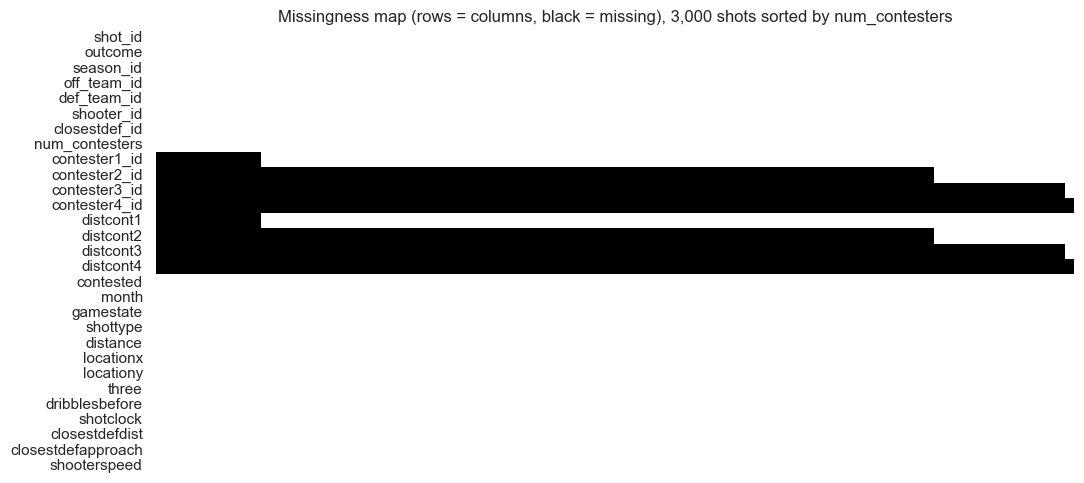

In [ ]:
#6 Missingness structure analysis
miss = pd.DataFrame({"train_%": train.isna().mean() * 100,
                     "test_%":  test.isna().mean() * 100}).round(2)
display(miss[(miss > 0).any(axis=1)])                 # show only columns that have any missing

#Sample 3000 shots (a full 425k-row heatmap would be unreadable), then sort so the

samp = train.sample(3000, random_state=SEED).sort_values("num_contesters")
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(samp.isna().T, cbar=False, yticklabels=True, xticklabels=False, cmap="Greys", ax=ax)
ax.set_title("Missingness map (rows = columns, black = missing), 3,000 shots sorted by num_contesters")
savefig("01_missingness_map")

outcome values: [np.False_, np.True_] | nulls: 0


,mean,size
season_id,,
2676a,0.459630,212458
fe055,0.456516,213261


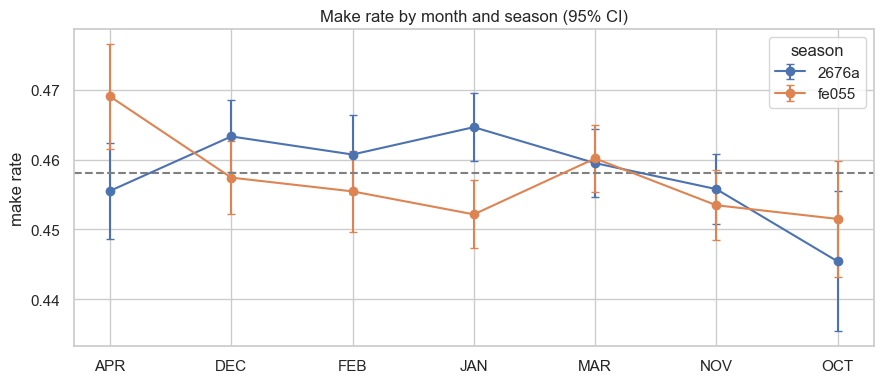

In [ ]:
#7 Outcome and season trends
print("outcome values:", sorted(train.outcome.unique()), "| nulls:", train.outcome.isna().sum())
display(train.groupby("season_id").outcome.agg(["mean", "size"]))

mon = train.groupby(["season_id", "month"]).outcome.agg(["mean", "size"]).reset_index()
mon["se"] = np.sqrt(mon["mean"] * (1 - mon["mean"]) / mon["size"])     # binomial standard error
fig, ax = plt.subplots(figsize=(9, 4))
for s, g in mon.groupby("season_id"):
    ax.errorbar(g["month"], g["mean"], yerr=1.96 * g["se"], marker="o", capsize=3, label=s)  #95% CI
ax.axhline(train.outcome.mean(), color="grey", ls="--")                #overall make rate
ax.set_ylabel("make rate"); ax.legend(title="season")
ax.set_title("Make rate by month and season (95% CI)")
savefig("02_target_by_month_season")

In [ ]:
#8 Train-test category comparison
for c in ["season_id", "month", "gamestate", "shottype", "off_team_id", "def_team_id"]:
    comp = pd.concat([train[c].value_counts(normalize=True).rename("train"),
                      test[c].value_counts(normalize=True).rename("test")], axis=1).fillna(0)
    print(f"\n{c}: {len(comp)} levels | only in test: {(comp.train == 0).sum()} | only in train: {(comp.test == 0).sum()}")
    if len(comp) <= 12:
        display(comp.round(3))              #small categoricals: show the full share table

for c in ["shooter_id", "closestdef_id"]:
    seen = set(train[c])                     #every ID present in training
    unseen = ~test[c].isin(seen)             #True where the test ID was never seen in training
    print(f"{c}: test rows with an ID never seen in train = {unseen.sum():,} ({100 * unseen.mean():.2f}%)")


season_id: 3 levels | only in test: 1 | only in train: 2


,train,test
season_id,,
fe055,0.501,0.0
2676a,0.499,0.0
d7a2d,0.000,1.0



month: 7 levels | only in test: 0 | only in train: 0


,train,test
month,,
MAR,0.189,0.193
JAN,0.188,0.184
NOV,0.178,0.180
DEC,0.165,0.155
FEB,0.139,0.145
APR,0.086,0.086
OCT,0.055,0.057



gamestate: 3 levels | only in test: 0 | only in train: 0


,train,test
gamestate,,
HALFCOURT,0.720,0.713
TRANSITION,0.206,0.214
DIRECTSECONDCHANCE,0.074,0.074



shottype: 7 levels | only in test: 0 | only in train: 0


,train,test
shottype,,
jumper,0.544,0.544
layup,0.271,0.265
floater,0.065,0.069
dunk,0.061,0.061
post,0.035,0.033
tip,0.022,0.023
heave,0.003,0.004



off_team_id: 30 levels | only in test: 0 | only in train: 0

def_team_id: 30 levels | only in test: 0 | only in train: 0
shooter_id: test rows with an ID never seen in train = 1,146 (0.54%)
closestdef_id: test rows with an ID never seen in train = 1,622 (0.76%)


In [ ]:
#9 Contester-field validation
def structural_check(df, name):
    dist_cols = [f"distcont{k}" for k in range(1, 5)]
    id_cols   = [f"contester{k}_id" for k in range(1, 5)]
    dist_filled = df[dist_cols].notna().sum(axis=1)       #how many distance slots are filled per row
    id_filled   = df[id_cols].notna().sum(axis=1)         #how many ID slots are filled per row

    # Slot k should only be filled if slot k-1 is also filled (no gaps).
    order_violations = 0
    for k in range(2, 5):
        order_violations += int((df[f"distcont{k}"].notna() & df[f"distcont{k-1}"].isna()).sum())

    return pd.Series({
        "distance slots != num_contesters":     int((dist_filled != df.num_contesters).sum()),
        "id slots != num_contesters":           int((id_filled != df.num_contesters).sum()),
        # The ID and distance for a given slot should be present/absent together.
        "id and distance filled differently":   int((df[dist_cols].notna().values != df[id_cols].notna().values).any(axis=1).sum()),
        "slots filled out of order":            order_violations,
        # 'contested' should be True exactly when there is at least one contester.
        "contested != (num_contesters > 0)":    int((df.contested.astype(int) != (df.num_contesters > 0).astype(int)).sum()),
    }, name=name)

pd.concat([structural_check(train, "train"), structural_check(test, "test")], axis=1)

,train,test
distance slots != num_contesters,0,0
id slots != num_contesters,0,0
id and distance filled differently,0,0
slots filled out of order,0,0
contested != (num_contesters > 0),0,0


In [ ]:
#10 Defender-approach parsing
def parse_approach(df):
    """Return (element_count, numeric_frame) for the closestdefapproach column."""
    s = df.closestdefapproach.str.strip().str.strip("{}")      #drop the curly braces
    n_elems = s.str.count(",") + 1                              #commas + 1 = number of elements
    parts = s.str.split(",", expand=True)                       #one column per element (as text)
    vals = parts.apply(pd.to_numeric, errors="coerce")          #text -> numbers; failures become NaN
    return n_elems, parts, vals

for name, df in [("train", train), ("test", test)]:
    n_elems, parts, vals = parse_approach(df)
    #A "failed cell" = text was present but did not convert to a number.
    failed = int((parts.notna() & vals.isna()).sum().sum())
    print(f"{name}: element counts = {n_elems.value_counts().to_dict()} | non-numeric cells = {failed}")

#Empircal check
_, _, v = parse_approach(train)
v.columns = ["a0", "a1", "a2", "a3"]                 #positions in the list, NOT yet assumed to be times
gap = pd.DataFrame({c: (v[c] - train.closestdefdist).abs() for c in v.columns}).describe().T[["mean", "50%", "75%"]]
display(gap.rename(columns={"50%": "median"}).round(3))   # gap between each element and release-time distance
display(v.corrwith(train.closestdefdist).rename("corr with closestdefdist").to_frame().round(3))

train: element counts = {4: 425719} | non-numeric cells = 0
test: element counts = {4: 213977} | non-numeric cells = 0


,mean,median,75%
a0,4.400,3.155,7.048
a1,3.377,2.437,5.333
a2,2.108,1.613,3.180
a3,1.125,0.909,1.661


,corr with closestdefdist
a0,0.618
a1,0.715
a2,0.841
a3,0.941


train                                                   \
                   count   mean    std    min   0.1%     1%    50%    99%   
distance        425719.0  14.77  10.07   0.01   0.23   0.77  14.55  29.70   
locationx       425719.0 -32.61   9.34 -53.33 -45.09 -43.79 -36.40 -13.54   
locationy       425719.0   0.36  12.19 -27.64 -24.02 -23.46   0.06  23.54   
shotclock       425719.0  12.39   5.62   0.00   0.00   0.00  12.77  24.00   
closestdefdist  425719.0   4.86   2.78   0.04   0.85   1.36   4.30  15.18   
shooterspeed    425719.0   4.48   4.16   0.00   0.06   0.21   2.75  15.95   
dribblesbefore  425719.0   2.35   3.54   0.00   0.00   0.00   1.00  16.00   
distcont1       379712.0   4.41   2.01   0.04   0.83   1.34   4.11  10.16   
distcont2        69703.0   4.20   1.31   0.57   1.67   2.14   3.98   8.36   
distcont3         4066.0   4.45   1.05   1.91   2.28   2.65   4.31   7.44   
distcont4           37.0   4.83   1.27   3.29   3.30   3.32   4.49   7.88   
num_contesters  425719.0   1.07   0.54   0.00   0.00   0.00   1.00   2.00   

                                  test                                     \
                99.9%    max     count   mean    std    min   0.1%     1%   
distance        46.25  89.90  213977.0  15.05  10.30   0.01   0.24   0.79   
locationx        2.22  46.25  213977.0 -32.37   9.66 -49.11 -45.14 -43.82   
locationy       24.11  26.73  213977.0   0.33  12.29 -26.83 -24.05 -23.47   
shotclock       24.00  24.00  213977.0  12.36   5.70   0.00   0.00   0.00   
closestdefdist  21.69  59.94  213977.0   4.88   2.80   0.04   0.86   1.36   
shooterspeed    18.35  23.98  213977.0   4.48   4.16   0.00   0.06   0.21   
dribblesbefore  23.00  36.00  213977.0   2.34   3.56   0.00   0.00   0.00   
distcont1       12.69  76.99  189891.0   4.42   2.00   0.04   0.84   1.33   
distcont2       10.66  36.94   33569.0   4.23   1.30   1.32   1.72   2.14   
distcont3        9.01  21.57    1856.0   4.48   1.26   2.20   2.33   2.66   
distcont4        8.10   8.12      13.0   4.96   1.09   3.45   3.46   3.50   
num_contesters   3.00   4.00  213977.0   1.05   0.54   0.00   0.00   0.00   

                                            
                  50%    99%  99.9%    max  
distance        15.06  30.49  60.13  89.09  
locationx      -36.27 -12.72  16.98  47.30  
locationy        0.03  23.55  24.10  26.70  
shotclock       12.73  24.00  24.00  24.00  
closestdefdist   4.34  15.38  22.03  63.01  
shooterspeed     2.74  15.93  18.31  22.09  
dribblesbefore   1.00  16.00  23.00  32.00  
distcont1        4.13  10.08  12.54  78.79  
distcont2        4.01   8.42  10.54  18.04  
distcont3        4.33   7.37  14.20  29.85  
distcont4        4.79   7.20   7.30   7.31  
num_contesters   1.00   2.00   3.00   4.00

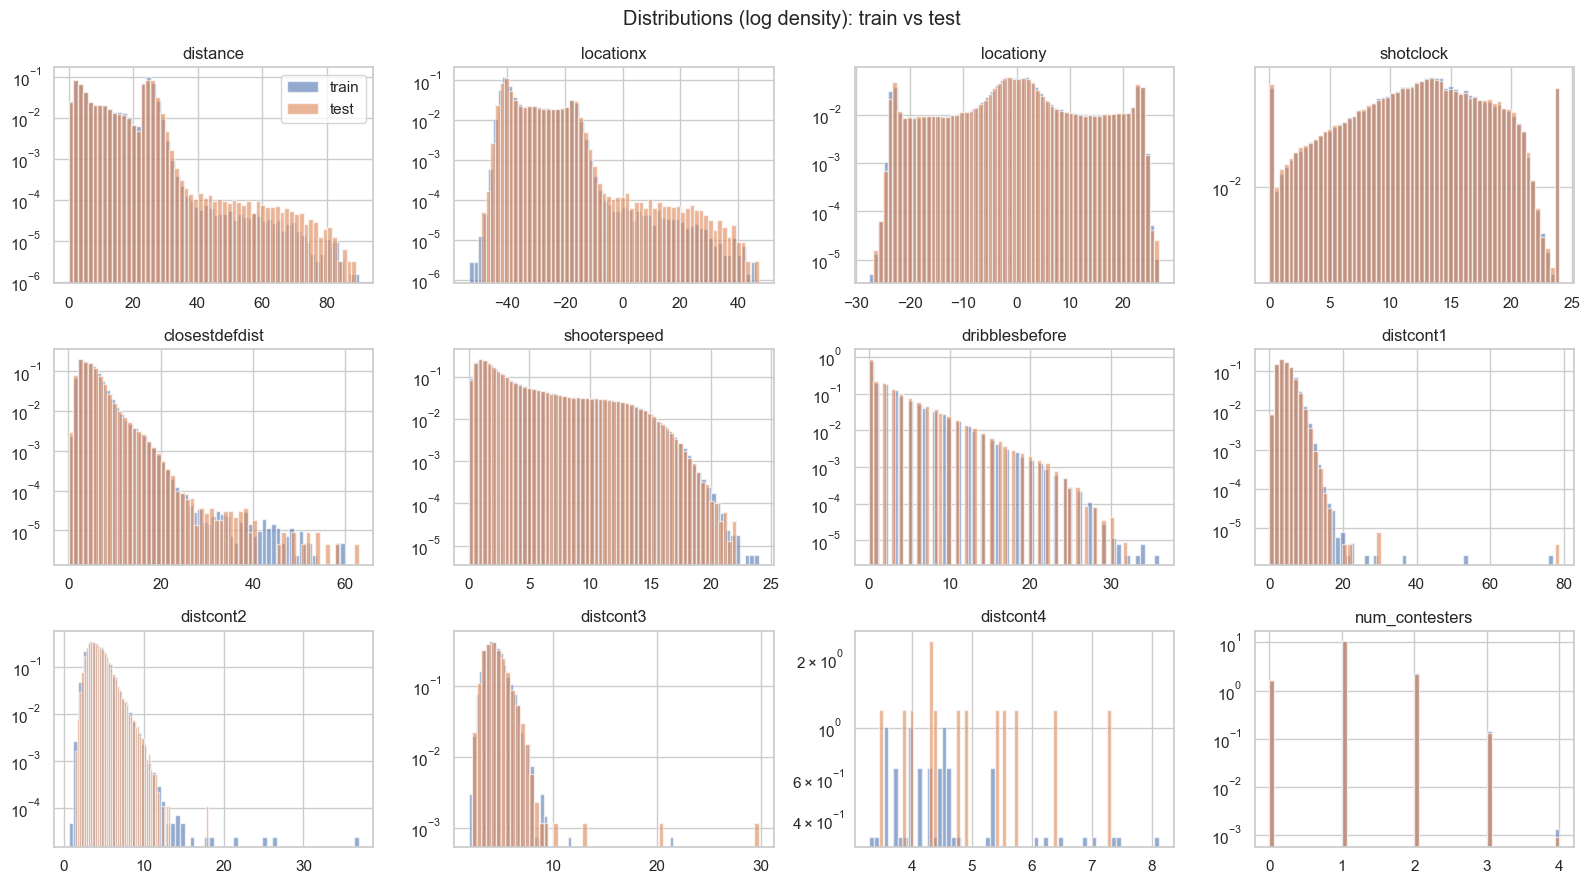

In [ ]:
#11 Numeric distribution checks
num_cols = ["distance", "locationx", "locationy", "shotclock", "closestdefdist", "shooterspeed",
            "dribblesbefore", "distcont1", "distcont2", "distcont3", "distcont4", "num_contesters"]

rng_tab = pd.concat({
    "train": train[num_cols].describe(percentiles=[.001, .01, .5, .99, .999]).T,
    "test":  test[num_cols].describe(percentiles=[.001, .01, .5, .99, .999]).T}, axis=1)
display(rng_tab.round(2))

fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, c in zip(axes.flat, num_cols):
    ax.hist(train[c].dropna(), bins=60, alpha=.6, density=True, label="train")   #density -> comparable despite size difference
    ax.hist(test[c].dropna(),  bins=60, alpha=.6, density=True, label="test")
    ax.set_title(c); ax.set_yscale("log")
axes.flat[0].legend()
fig.suptitle("Distributions (log density): train vs test")
savefig("03_distributions")

fit on raw x : hoop=(-41.75,0.00)  median |resid|=0.000 ft
fit on |x|   : hoop=(41.75,0.00)  median |resid|=0.001 ft
locationx range: -53.33 46.25 | locationy range: -27.64 26.73


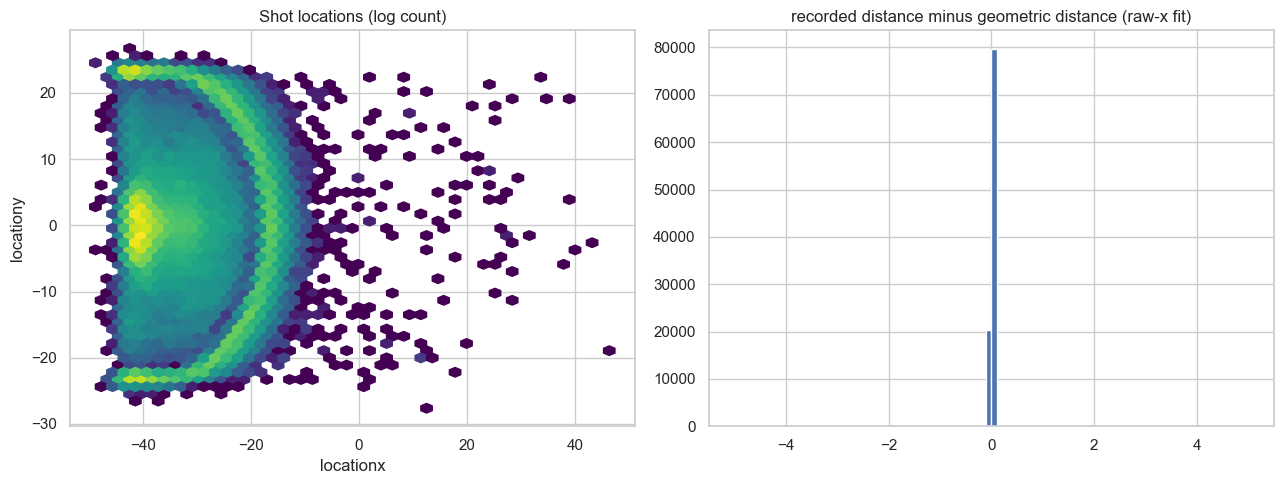

In [ ]:
#12 Court-coordinate validation
samp = train.sample(100_000, random_state=SEED)      #100k rows is plenty and keeps this fast

def fit_hoop(x, y, d):
    """Fit hoop location; return (hoop_xy, residuals) where residual = geometric dist - recorded dist."""
    f = lambda p: np.hypot(x - p[0], y - p[1]) - d
    r = optimize.least_squares(f, x0=[0.0, 0.0], loss="soft_l1")   
    return r.x, f(r.x)

(hx, hy),   res_raw = fit_hoop(samp.locationx.values,          samp.locationy.values, samp.distance.values)
(hx2, hy2), res_abs = fit_hoop(np.abs(samp.locationx.values),  samp.locationy.values, samp.distance.values)
print(f"fit on raw x : hoop=({hx:.2f},{hy:.2f})  median |resid|={np.median(np.abs(res_raw)):.3f} ft")
print(f"fit on |x|   : hoop=({hx2:.2f},{hy2:.2f})  median |resid|={np.median(np.abs(res_abs)):.3f} ft")
print("locationx range:", train.locationx.min(), train.locationx.max(),
      "| locationy range:", train.locationy.min(), train.locationy.max())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hexbin(samp.locationx, samp.locationy, gridsize=45, bins="log", cmap="viridis")  #density of shot locations
axes[0].set_title("Shot locations (log count)"); axes[0].set_xlabel("locationx"); axes[0].set_ylabel("locationy")
axes[1].hist(res_raw, bins=100, range=(-5, 5))
axes[1].set_title("recorded distance minus geometric distance (raw-x fit)")
savefig("04_geometry")

In [ ]:
#13 Cross-feature consistency checks
cont_id_cols = ["contester1_id", "contester2_id", "contester3_id", "contester4_id"]
dc = train[[f"distcont{k}" for k in range(1, 5)]]

cons = {}
cons["shooter == closest defender"]  = int((train.shooter_id == train.closestdef_id).sum())
cons["off_team == def_team"]         = int((train.off_team_id == train.def_team_id).sum())
cons["closest defender is contester1"]   = f"{100 * (train.closestdef_id == train.contester1_id).mean():.1f}% of all shots"
cons["closest defender in any contester slot"] = f"{100 * train[cont_id_cols].eq(train.closestdef_id, axis=0).any(axis=1).mean():.1f}%"
#diff(axis=1) < 0 means a later contester is CLOSER than an earlier one, i.e. not sorted ascending.
cons["contester distances not ascending"] = int((dc.diff(axis=1) < 0).any(axis=1).sum())
cons["|distcont1 - closestdefdist| > 0.5 ft"] = int(((train.distcont1 - train.closestdefdist).abs() > 0.5).sum())
display(pd.Series(cons, name="count / share").to_frame())

#Does the `three` flag agree with distance? (3pt line is ~22 ft in corners, ~23.75 ft elsewhere;
#we REPORT how the flag behaves rather than assuming it is right.)
bins = [0, 20, 22, 23.75, 25, 30, 100]
t3 = train.groupby(pd.cut(train.distance, bins), observed=True).three.agg(["mean", "size"])
display(t3.rename(columns={"mean": "share flagged as 3pt"}))

,count / share
shooter == closest defender,0
off_team == def_team,0
closest defender is contester1,86.7% of all shots
closest defender in any contester slot,86.7%
contester distances not ascending,0
|distcont1 - closestdefdist| > 0.5 ft,6305


,share flagged as 3pt,size
distance,,
"(0.0, 20.0]",0.000000,241667
"(20.0, 22.0]",0.000000,4264
"(22.0, 23.75]",0.929002,42635
"(23.75, 25.0]",1.000000,38883
"(25.0, 30.0]",1.000000,94713
"(30.0, 100.0]",1.000000,3557


In [ ]:
#14 Train-test shift classifier
#Fix the category order using train + test together, so category codes mean the same in both.
CATS = {c: sorted(set(train[c]) | set(test[c])) for c in ["month", "gamestate", "shottype"]}
NUM = ["distance", "locationx", "locationy", "shotclock", "closestdefdist", "shooterspeed", "dribblesbefore",
       "num_contesters", "distcont1", "distcont2", "distcont3", "distcont4", "three", "contested"]

def design(df):
    """Numeric feature matrix used for drift and validation experiments (no IDs, no season)."""
    X = df[NUM].astype(float).copy()                                   #bools become 0/1 floats
    for c, cats in CATS.items():
        X[c] = pd.Categorical(df[c], categories=cats).codes            #text category -> integer code
    return X

def adv_auc(a, b, n=100_000):
    """Cross-validated AUC of a classifier separating dataset a (label 0) from b (label 1)."""
    a = a.sample(min(n, len(a)), random_state=SEED)                    #equal-ish sizes keep AUC interpretable
    b = b.sample(min(n, len(b)), random_state=SEED)
    X = pd.concat([design(a), design(b)])
    y = np.r_[np.zeros(len(a)), np.ones(len(b))]
    oof = np.zeros(len(y))                                             #out-of-fold predictions (never predicts its own training rows)
    for tr_i, va_i in StratifiedKFold(3, shuffle=True, random_state=SEED).split(X, y):
        m = HistGradientBoostingClassifier(max_iter=100, random_state=SEED).fit(X.iloc[tr_i], y[tr_i])
        oof[va_i] = m.predict_proba(X.iloc[va_i])[:, 1]
    return roc_auc_score(y, oof)

s1, s2 = sorted(train.season_id.unique())          
A = train[train.season_id == s1]; B = train[train.season_id == s2]
auc_ref = adv_auc(A, B)                            
auc_A   = adv_auc(A, test)                         
auc_B   = adv_auc(B, test)                         
print(f"reference AUC ({s1} vs {s2}): {auc_ref:.3f}")
print(f"{s1} vs test: {auc_A:.3f} | {s2} vs test: {auc_B:.3f}")

reference AUC (2676a vs fe055): 0.544
2676a vs test: 0.537 | fe055 vs test: 0.520


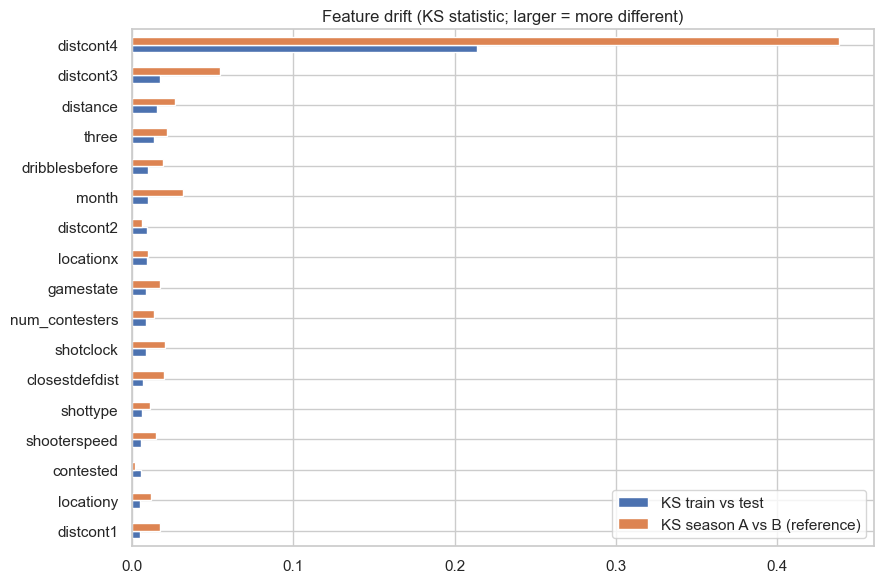

In [ ]:
#15 Feature distribution shift
Xt, Xe = design(train), design(test)
XA_, XB_ = design(A), design(B)

def ks_stat(a, b, n=50_000):
    """KS statistic on up-to-n random samples of each (missing values dropped)."""
    a, b = a.dropna(), b.dropna()
    return stats.ks_2samp(a.sample(min(n, len(a)), random_state=SEED),
                          b.sample(min(n, len(b)), random_state=SEED)).statistic

dr = pd.DataFrame({
    "KS train vs test":               {c: ks_stat(Xt[c],  Xe[c])  for c in Xt.columns},
    "KS season A vs B (reference)":   {c: ks_stat(XA_[c], XB_[c]) for c in Xt.columns},
}).sort_values("KS train vs test")

dr.plot.barh(figsize=(9, 6))
plt.title("Feature drift (KS statistic; larger = more different)")
savefig("05_feature_drift")

shot_id range: 1 - 639696 | rows: 639696


,adjacent_same,expected_if_random,ratio
column,,,
split,0.5548,0.5549,0.9998
season_id,0.3329,0.3331,0.9993
month,0.1593,0.1595,0.9988
off_team_id,0.0332,0.0333,0.9952
def_team_id,0.0331,0.0334,0.9931
shooter_id,0.0030,0.0029,1.0205
closestdef_id,0.0023,0.0025,0.9458
gamestate,0.5647,0.5640,1.0013


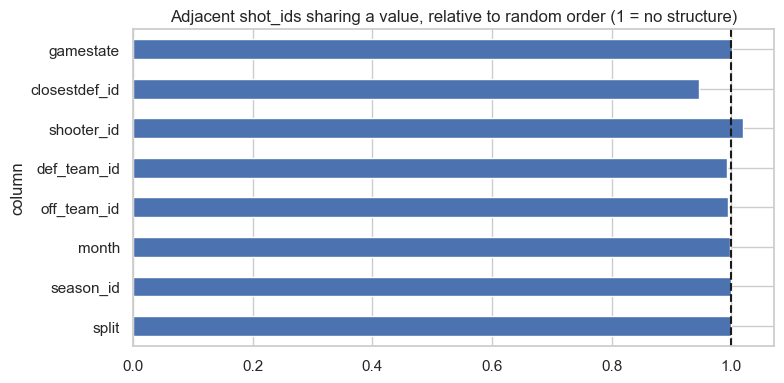

In [ ]:
#16 Shot-ID ordering investigation
allshots = (pd.concat([train.assign(split="train"), test.assign(split="test")])
              .sort_values("shot_id").reset_index(drop=True))
print("shot_id range:", allshots.shot_id.min(), "-", allshots.shot_id.max(), "| rows:", len(allshots))

def adj_rate(a):
    """Fraction of consecutive pairs (row i, row i+1) that have the same value."""
    a = np.asarray(a)
    return (a[1:] == a[:-1]).mean()

out = []
for c in ["split", "season_id", "month", "off_team_id", "def_team_id", "shooter_id", "closestdef_id", "gamestate"]:
    obs = adj_rate(allshots[c])                                                   #real order
    perm = [adj_rate(rng.permutation(allshots[c].values)) for _ in range(30)]     #random orders => chance baseline
    out.append(dict(column=c, adjacent_same=obs, expected_if_random=np.mean(perm),
                    ratio=obs / np.mean(perm)))
adj = pd.DataFrame(out).set_index("column")
display(adj.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
adj["ratio"].plot.barh(ax=ax)
ax.axvline(1, color="k", ls="--")                         #1 = no structure
ax.set_title("Adjacent shot_ids sharing a value, relative to random order (1 = no structure)")
savefig("06_shotid_adjacency")

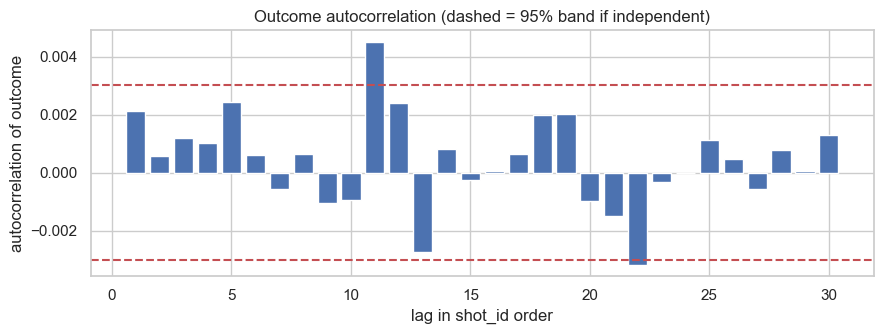

In [ ]:
#17 Outcome autocorrelation check
ts = train.sort_values("shot_id").outcome.astype(float).values     #outcomes in shot_id order
lags = range(1, 31)
ac = [np.corrcoef(ts[:-k], ts[k:])[0, 1] for k in lags]            #correlation of series with itself shifted by k
band = 1.96 / np.sqrt(len(ts))                                     #approximate 95% band under independence

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(list(lags), ac)
ax.axhline(band, color="r", ls="--"); ax.axhline(-band, color="r", ls="--")
ax.set_xlabel("lag in shot_id order"); ax.set_ylabel("autocorrelation of outcome")
ax.set_title("Outcome autocorrelation (dashed = 95% band if independent)")
savefig("07_outcome_autocorr")

In [ ]:
#18 Proxy-game dependence analysis
for d in (train, test):
    d["pgame"] = d.season_id + "|" + d.off_team_id + "|" + d.def_team_id + "|" + d.month   #proxy game key

g = train.groupby("pgame").outcome.agg(s="sum", m="count")      # per group: number made (s) and shots (m)
print("proxy groups:", len(g), "| shots per group:", g.m.describe()[["min", "50%", "mean", "max"]].round(1).to_dict())

N, G = g.m.sum(), len(g)               #total shots, number of groups
p = train.outcome.mean()               #overall make rate
ybar_g = g.s / g.m                     #make rate within each group

# One-way ANOVA estimator of the intra-class correlation for unequal group sizes:
MSB = (g.m * (ybar_g - p) ** 2).sum() / (G - 1)         #mean square BETWEEN groups
MSW = (g.s - g.s ** 2 / g.m).sum() / (N - G)            #mean square WITHIN groups (binary y: sum(y^2) = sum(y))
m0  = (N - (g.m ** 2).sum() / N) / (G - 1)              #effective group size for unbalanced groups
icc = (MSB - MSW) / (MSB + (m0 - 1) * MSW)
deff = 1 + (g.m.mean() - 1) * icc                       #design effect

se_naive = np.sqrt(p * (1 - p) / N)                     #SE if every shot were independent
resid_sum = g.s - p * g.m                               #each group's total deviation from the overall rate
se_cluster = np.sqrt((resid_sum ** 2).sum()) / N * np.sqrt(G / (G - 1))   #cluster-robust SE of the make rate

print(f"ICC(1) of outcome within proxy groups: {icc:.4f}")
print(f"design effect: {deff:.2f}")
print(f"naive SE {se_naive:.5f}  vs  cluster-robust SE {se_cluster:.5f}  (x{se_cluster / se_naive:.2f})")

proxy groups: 4192 | shots per group: {'min': 64.0, '50%': 88.0, 'mean': 101.6, 'max': 284.0}
ICC(1) of outcome within proxy groups: 0.0010
design effect: 1.10
naive SE 0.00076  vs  cluster-robust SE 0.00081  (x1.06)


done in 62s


,mean,min,max
Random 5-fold,0.62721,0.62618,0.63035
Contiguous shot_id blocks,0.62724,0.62529,0.62885
Grouped by proxy game,0.62744,0.62711,0.62770
Grouped by shooter,0.62746,0.62594,0.62901
Season holdout (both ways),0.62840,0.62680,0.63000


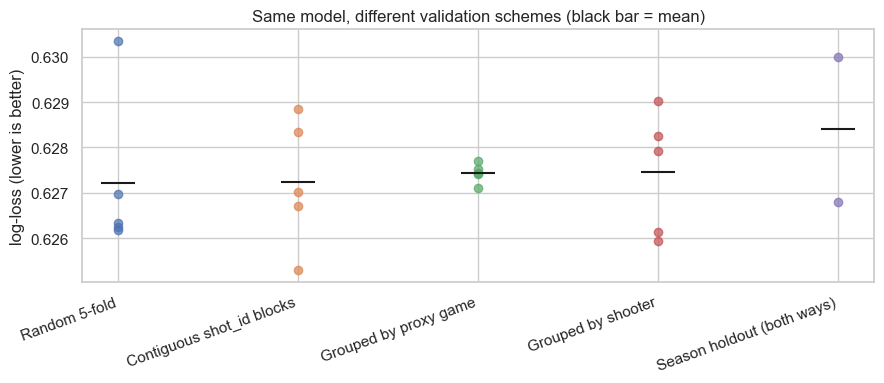

In [ ]:
#19 Validation strategy comparison
X = design(train); y = train.outcome.values
order = np.argsort(train.shot_id.values)               #row positions sorted by shot_id

def contiguous_blocks(k=5):
    """k folds made of consecutive shot_id ranges (fold i = i-th block)."""
    parts = np.array_split(order, k)
    return [(np.concatenate([parts[j] for j in range(k) if j != i]), parts[i]) for i in range(k)]

idxA = np.where(train.season_id.values == s1)[0]       #row positions of season A
idxB = np.where(train.season_id.values == s2)[0]       #row positions of season B

schemes = {
    "Random 5-fold":              list(KFold(5, shuffle=True, random_state=SEED).split(X)),
    "Contiguous shot_id blocks":  contiguous_blocks(5),
    "Grouped by proxy game":      list(GroupKFold(5).split(X, y, groups=train.pgame)),
    "Grouped by shooter":         list(GroupKFold(5).split(X, y, groups=train.shooter_id)),
    "Season holdout (both ways)": [(idxA, idxB), (idxB, idxA)],     #train on A -> score B, then train on B -> score A
}

def eval_scheme(splits):
    """Fit the model on each training index set and return log-loss on each validation set."""
    scores = []
    for tr_i, va_i in splits:
        m = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.1, random_state=SEED)
        m.fit(X.iloc[tr_i], y[tr_i])
        scores.append(log_loss(y[va_i], m.predict_proba(X.iloc[va_i])[:, 1]))
    return scores

t0 = time.time()
results = {k: eval_scheme(v) for k, v in schemes.items()}
print(f"done in {time.time() - t0:.0f}s")
res = pd.DataFrame({k: {"mean": np.mean(v), "min": np.min(v), "max": np.max(v)} for k, v in results.items()}).T
display(res.round(5))

fig, ax = plt.subplots(figsize=(9, 4))
for i, (k, v) in enumerate(results.items()):
    ax.scatter([i] * len(v), v, alpha=.7)                        # each dot = one fold
    ax.scatter(i, np.mean(v), marker="_", s=600, color="k")      # black bar = scheme mean
ax.set_xticks(range(len(results))); ax.set_xticklabels(results.keys(), rotation=20, ha="right")
ax.set_ylabel("log-loss (lower is better)")
ax.set_title("Same model, different validation schemes (black bar = mean)")
savefig("08_validation_scheme_comparison")

In [ ]:
#20 Data-cleaning policy

#(low, high) limits from physics / the rules of the game. None = no bound on that side.
#These are NOT chosen from the data distribution or from model results.
HARD_LIMITS = {
    "shotclock":      (0, 24),        # the shot clock runs from 24 down to 0
    "distance":       (0, 94),        # cannot be negative or longer than the court
    "closestdefdist": (0, 94),
    "distcont1": (0, 94), "distcont2": (0, 94), "distcont3": (0, 94), "distcont4": (0, 94),
    "shooterspeed":   (0, 35),        #ft/s; above elite sprint speed is not physical
    "dribblesbefore": (0, None),      #cannot be negative; no upper bound
}
APP = ["app_100", "app_075", "app_050", "app_025"]   #parsed approach columns; order verified in Cell 10


def clean(df, name):
    """Apply the data policy to one dataset. `name` ('train' or 'test') is only used in the change log."""
    d = df.copy()                                    #never modify the caller's dataframe

    #1) Types: booleans -> 0/1 integers. `outcome` exists in train only, so check first.
    for c in ["three", "contested"] + (["outcome"] if "outcome" in d else []):
        d[c] = d[c].astype(int)

    #2) Parse closestdefapproach into four numeric columns. Any row that does not yield exactly
    #four numbers becomes all-NaN (and is logged). Cell 10 showed zero such rows.
    n_elems, _, vals = parse_approach(d)             #helper defined in Cell 10
    vals.columns = APP
    bad_parse = vals.isna().any(axis=1) | (n_elems != 4)
    vals.loc[bad_parse, :] = np.nan
    log_change(f"{name}: parse approach", "closestdefapproach", bad_parse.sum(),
               "set NaN where not 4 numeric values")
    d = pd.concat([d.drop(columns=["closestdefapproach"]), vals], axis=1)

    #3) Hard limits: impossible values -> NaN, plus a flag column so a model can see they were altered.
    for c, (lo, hi) in HARD_LIMITS.items():
        bad = pd.Series(False, index=d.index)
        if lo is not None: bad |= d[c] < lo
        if hi is not None: bad |= d[c] > hi
        d[f"{c}_flag"] = bad.astype(int)
        log_change(f"{name}: hard limit", c, bad.sum(), f"set NaN (outside {lo}..{hi}) + flag")
        d.loc[bad, c] = np.nan
    for c in APP:                                    #approach distances cannot be negative either
        bad = d[c] < 0
        log_change(f"{name}: hard limit", c, bad.sum(), "set NaN (negative distance)")
        d.loc[bad, c] = np.nan

    # 4) Structural indicators and regime flags.
    for k in range(1, 5):
        d[f"has_cont{k}"] = (d.num_contesters >= k).astype(int)   #does contester k exist?

    #AMENDMENT A1: the shot clock has valid point masses at exactly 24 (putbacks) and exactly 0
    #(expired / off clock) that behave like separate regimes. Keep the raw value; add indicators.
    d["sc_is_24"] = (d.shotclock == 24).astype(int)
    d["sc_is_0"]  = (d.shotclock == 0).astype(int)

    #AMENDMENT A2: coordinates outside the court are flagged, NOT altered.
    #An NBA court is 94 ft x 50 ft, so |x| <= 47 and |y| <= 25 (physical facts).
    d["out_of_court"] = ((d.locationx < -47) | (d.locationx > 47) | (d.locationy.abs() > 25)).astype(int)
    for c in ["sc_is_24", "sc_is_0", "out_of_court"]:
        log_change(f"{name}: amendment flag", c, d[c].sum(), "flag column added; values unchanged")

    return d


#Apply from both datasets
#Exact duplicates are only ever dropped from TRAIN. `shot_id` is excluded from the comparison because
#it is unique by construction, and `pgame` because it is a helper column added in Cell 18.
dup_cols = [c for c in train.columns if c not in ("shot_id", "pgame")]
n_dup = int(train.duplicated(subset=dup_cols).sum())
log_change("train: duplicates", "all", n_dup, "dropped exact duplicate rows" if n_dup else "none found")
train_c = clean(train.drop_duplicates(subset=dup_cols), "train")
test_c  = clean(test, "test")                       # test rows are NEVER dropped (submission needs all of them)


LIN_COLS = ["distance", "locationx", "locationy", "shotclock", "closestdefdist", "shooterspeed",
            "dribblesbefore", "distcont1", "distcont2", "distcont3", "distcont4"] + APP
CONT_DIST = [f"distcont{k}" for k in range(1, 5)]
STATS = {"median": train_c[LIN_COLS].median(),      #fill value for genuinely missing entries
         "lo":     train_c[LIN_COLS].quantile(.001),  #winsorizing floor (0.1th percentile)
         "hi":     train_c[LIN_COLS].quantile(.999)}  #winsorizing cap (99.9th percentile)


def linear_view(d):
    """Imputed and winsorized copy for linear / neural models. Tree models use train_c / test_c directly."""
    v = d.copy()
    for c in CONT_DIST:
        v[c] = v[c].fillna(0)                       #absent contester -> 0; has_cont{k} says it is absent
    for c in LIN_COLS:
        #Record which values were missing BEFORE filling. Not needed for contester distances,
        #because the has_cont{k} indicators already carry that information.
        v[f"{c}_wasna"] = 0 if c in CONT_DIST else v[c].isna().astype(int)
        v[c] = v[c].fillna(STATS["median"][c]).clip(STATS["lo"][c], STATS["hi"][c])
    return v

In [ ]:
#21 Cleaning pipeline implementation

#NaNs we EXPECT to remain: contester fields (structural absence) and any column that could hold a
#value flagged as impossible. Everything else must be complete.
allowed_nan = ({f"distcont{k}" for k in range(1, 5)} | {f"contester{k}_id" for k in range(1, 5)}
               | set(HARD_LIMITS) | set(APP))
for name, d in [("train_c", train_c), ("test_c", test_c)]:
    nan_cols = set(d.columns[d.isna().any()])
    print(name, "| unexpected NaN columns:", sorted(nan_cols - allowed_nan) or "none")

#Schema and ordering: test must mirror train (minus outcome), and its row order must not have changed,
#because the submission file is matched to it row by row.
assert list(test_c.columns) == [c for c in train_c.columns if c != "outcome"], "train/test schema mismatch"
assert (test_c.shot_id.values == sub.shot_id.values).all(), "test row order changed (submission would misalign!)"

#Amendment checks: the new flag columns exist in BOTH datasets and are strictly 0/1.
for name, d in [("train_c", train_c), ("test_c", test_c)]:
    for c in ["sc_is_24", "sc_is_0", "out_of_court"]:
        assert set(d[c].unique()) <= {0, 1}, f"{name}.{c} is not binary"
    print(name, "flag counts:", {c: int(d[c].sum()) for c in ["sc_is_24", "sc_is_0", "out_of_court"]})

#The linear-model view must contain no NaN in the columns it promises to have filled.
lv_tr, lv_te = linear_view(train_c), linear_view(test_c)
assert not lv_tr[LIN_COLS].isna().any().any() and not lv_te[LIN_COLS].isna().any().any(), "NaN left after imputation"
print("shapes:", train_c.shape, test_c.shape, "| linear views:", lv_tr.shape, lv_te.shape)

#Change log: show steps that changed something, plus the duplicates line even when it is zero.
pd.DataFrame(CHANGELOG).query("rows_affected > 0 or step.str.contains('duplicates')")

train_c | unexpected NaN columns: none
test_c | unexpected NaN columns: none
train_c flag counts: {'sc_is_24': 10107, 'sc_is_0': 9837, 'out_of_court': 78}
test_c flag counts: {'sc_is_24': 5113, 'sc_is_0': 5362, 'out_of_court': 49}
shapes: (425719, 49) (213977, 48) | linear views: (425719, 64) (213977, 63)


,step,column,rows_affected,action
0,train: duplicates,all,0,none found
15,train: amendment flag,sc_is_24,10107,flag column added; values unchanged
16,train: amendment flag,sc_is_0,9837,flag column added; values unchanged
17,train: amendment flag,out_of_court,78,flag column added; values unchanged
32,test: amendment flag,sc_is_24,5113,flag column added; values unchanged
33,test: amendment flag,sc_is_0,5362,flag column added; values unchanged
34,test: amendment flag,out_of_court,49,flag column added; values unchanged


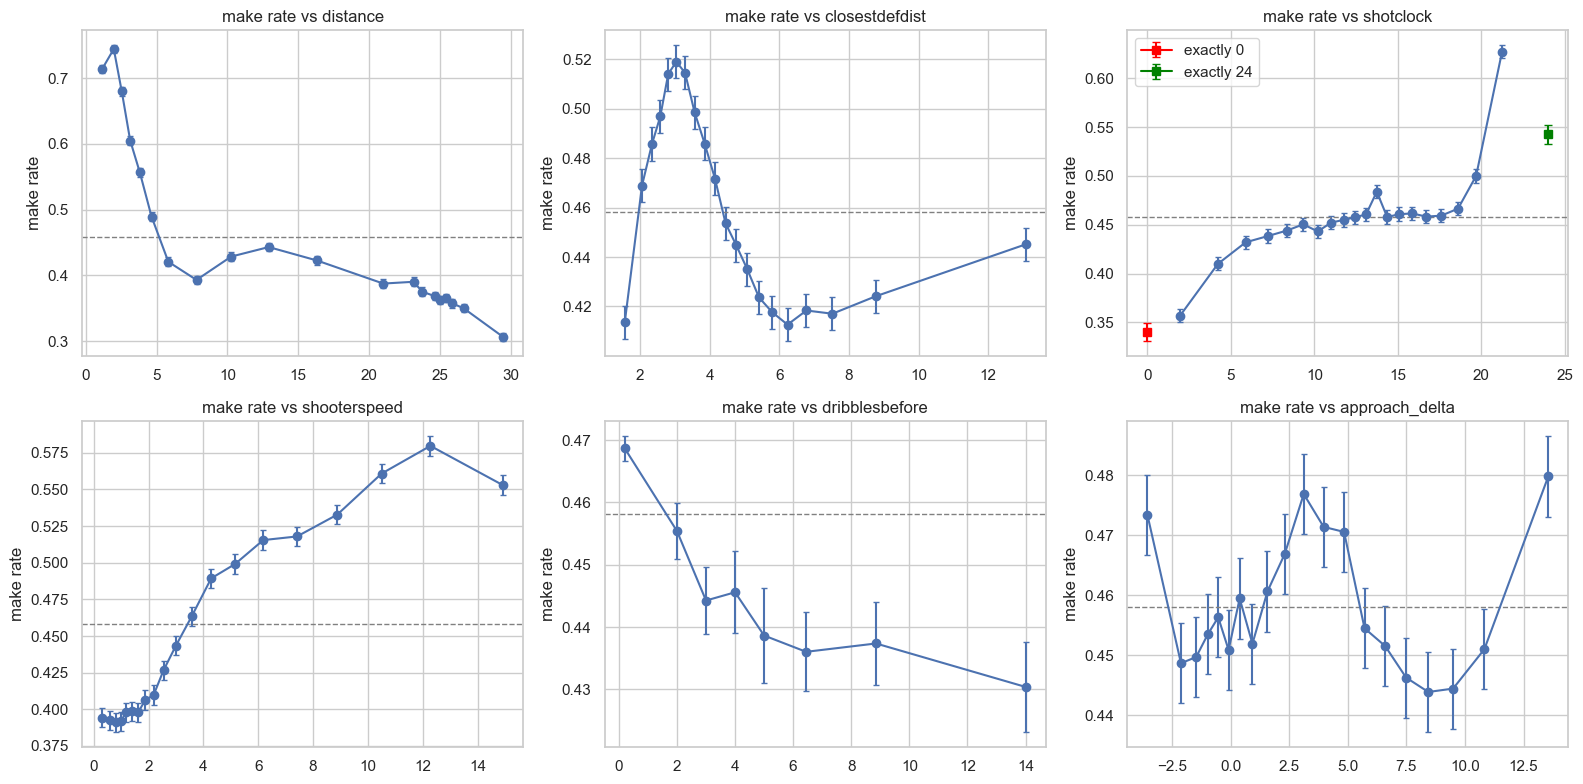

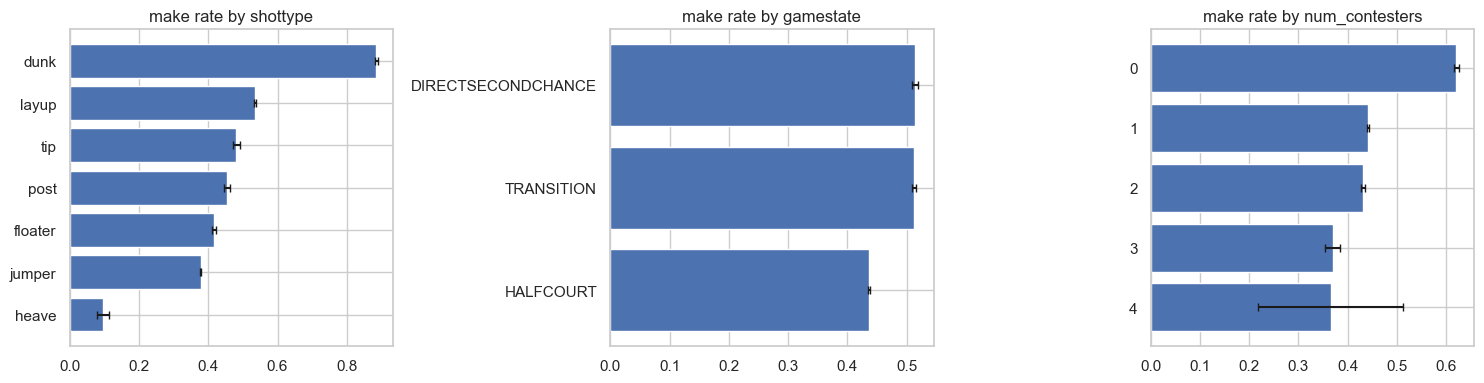

In [ ]:
#22 Clean-data validation
tc = train_c.copy()                                   #working copy; train_c itself stays untouched
tc["approach_delta"] = tc.app_100 - tc.closestdefdist

def wilson(k, n, z=1.96):
    """Wilson score interval for a proportion k/n. Returns (centre, half-width)."""
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre, half

def binned_rate(df, col, q=20):
    """Make rate by equal-count (quantile) bin of `col`; x = the mean of `col` inside each bin."""
    b = pd.qcut(df[col], q, duplicates="drop")        #duplicates="drop" merges bins when many values tie
    g = df.groupby(b, observed=True).agg(x=(col, "mean"), k=("outcome", "sum"), n=("outcome", "size"))
    g["p"], g["h"] = wilson(g.k, g.n)
    return g

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
plots = ["distance", "closestdefdist", "shotclock", "shooterspeed", "dribblesbefore", "approach_delta"]
for ax, col in zip(axes.flat, plots):
    d = tc[~tc.shotclock.isin([0, 24])] if col == "shotclock" else tc    #smooth curve excludes the spikes
    g = binned_rate(d, col)
    ax.errorbar(g.x, g.p, yerr=g.h, marker="o", capsize=2)
    if col == "shotclock":                                               #the two spikes as separate points
        for v, colr in [(0, "red"), (24, "green")]:
            s = tc[tc.shotclock == v]
            pc, h = wilson(s.outcome.sum(), len(s))
            ax.errorbar([v], [pc], yerr=[h], marker="s", color=colr, capsize=3, label=f"exactly {v}")
        ax.legend()
    ax.axhline(tc.outcome.mean(), color="grey", ls="--", lw=1)           #overall make rate for reference
    ax.set_title(f"make rate vs {col}"); ax.set_ylabel("make rate")
savefig("09_make_rate_vs_features")

#Categorical drivers: shot type, game state, number of contesters (95% intervals)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["shottype", "gamestate", "num_contesters"]):
    g = tc.groupby(col).outcome.agg(k="sum", n="size")
    g["p"], g["h"] = wilson(g.k, g.n)
    g = g.sort_values("p")
    ax.barh(g.index.astype(str), g.p, xerr=g.h, capsize=3)
    ax.set_title(f"make rate by {col}")
savefig("10_make_rate_categorical")

noise floor: 0.0024% of outcome uncertainty


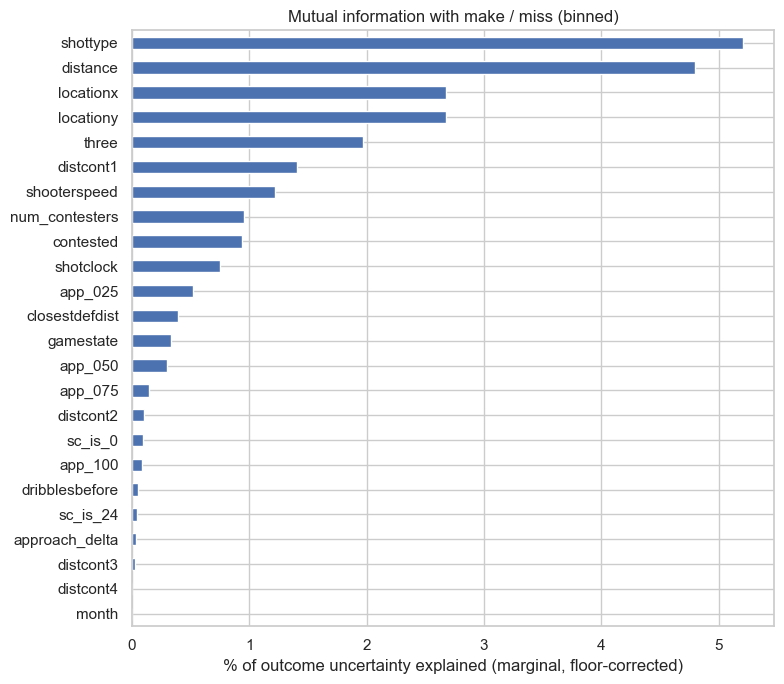

,MI %
shottype,5.210
distance,4.796
locationx,2.678
locationy,2.677
three,1.970
distcont1,1.404
shooterspeed,1.222
num_contesters,0.953
contested,0.936
shotclock,0.747


In [ ]:
#23 Univariate make-rate analysis
from sklearn.metrics import mutual_info_score

cols_mi = design(tc).join(tc[["app_100", "app_075", "app_050", "app_025",
                              "approach_delta", "sc_is_24", "sc_is_0"]])   #NaNs are KEPT here

def to_bins(s, q=20):
    """Integer bin codes for a column. Few unique values -> used as they are; otherwise q quantile bins.
    NaN becomes its own code (-1)."""
    if s.nunique() <= 20:
        return s.astype("category").cat.codes.values
    return pd.qcut(s, q, duplicates="drop").cat.codes.values

y_all = tc.outcome.values
p = y_all.mean()
H = -(p * np.log(p) + (1 - p) * np.log(1 - p))                 #entropy of the outcome, in nats

binned = {c: to_bins(cols_mi[c]) for c in cols_mi.columns}
mi_raw = pd.Series({c: mutual_info_score(binned[c], y_all) for c in binned})

#Noise floor: average MI when the outcome is shuffled (no true relationship possible).
floor = np.mean([np.mean([mutual_info_score(b, rng.permutation(y_all)) for b in binned.values()])
                 for _ in range(3)])
mi_pct = ((mi_raw - floor) / H * 100).clip(lower=0).sort_values()
print(f"noise floor: {floor / H * 100:.4f}% of outcome uncertainty")

mi_pct.plot.barh(figsize=(8, 7))
plt.xlabel("% of outcome uncertainty explained (marginal, floor-corrected)")
plt.title("Mutual information with make / miss (binned)")
savefig("11_mutual_information")
display(mi_pct.sort_values(ascending=False).round(3).to_frame("MI %"))

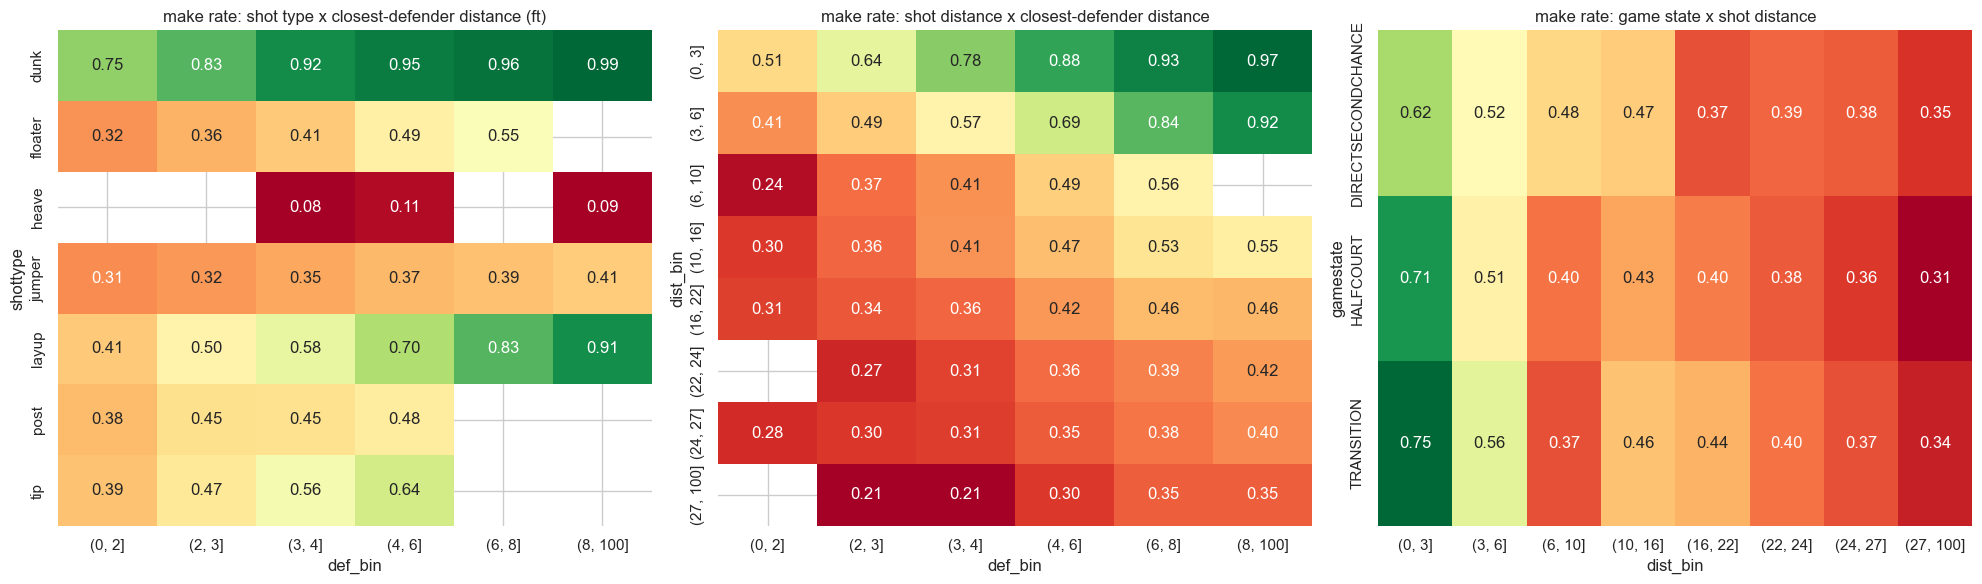

In [ ]:
#24 Mutual information analysis
tc["def_bin"]  = pd.cut(tc.closestdefdist, [0, 2, 3, 4, 6, 8, 100])           #closest-defender distance bands (ft)
tc["dist_bin"] = pd.cut(tc.distance, [0, 3, 6, 10, 16, 22, 24, 27, 100])      #shot-distance bands (ft)

def heat(index, columns, ax, title, min_n=200):
    """Heatmap of make rate over two variables, blanking cells with fewer than min_n shots."""
    rate = tc.pivot_table(index=index, columns=columns, values="outcome", aggfunc="mean", observed=True)
    cnt  = tc.pivot_table(index=index, columns=columns, values="outcome", aggfunc="size", observed=True)
    sns.heatmap(rate.where(cnt >= min_n), annot=True, fmt=".2f", cmap="RdYlGn", ax=ax, cbar=False)
    ax.set_title(title)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
heat("shottype",  "def_bin",  axes[0], "make rate: shot type x closest-defender distance (ft)")
heat("dist_bin",  "def_bin",  axes[1], "make rate: shot distance x closest-defender distance")
heat("gamestate", "dist_bin", axes[2], "make rate: game state x shot distance")
savefig("12_interactions")

context-only out-of-fold log-loss: 0.62614
shooter           players= 308  Pearson=0.528  Spearman=0.536  true-effect SD=0.0299  shrinkage k=246 shots
closest defender  players= 321  Pearson=0.351  Spearman=0.357  true-effect SD=0.0205  shrinkage k=524 shots


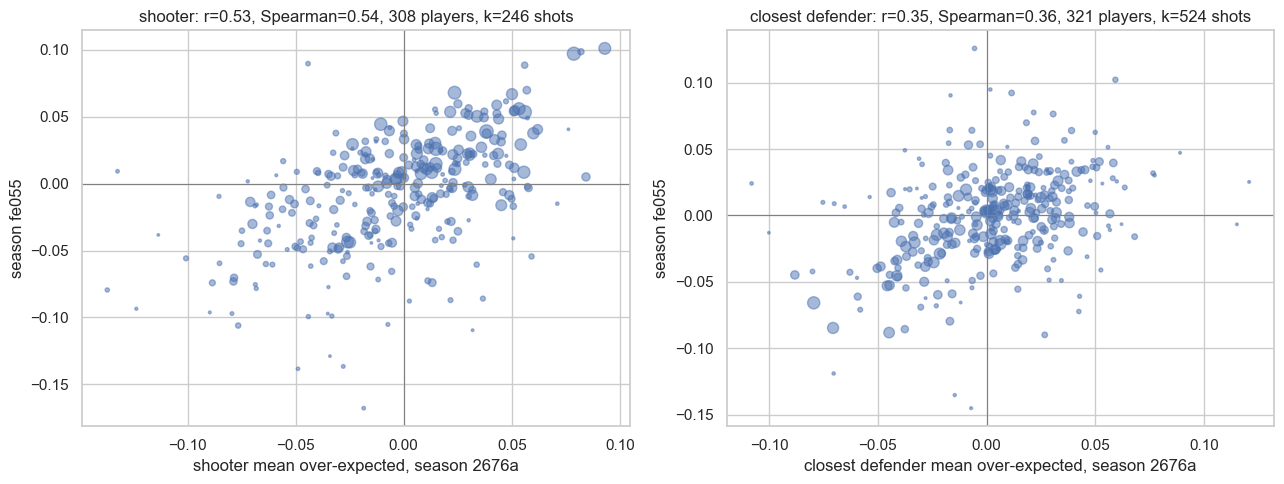

,shooter,closest defender
player shots,,
50,0.17,0.09
100,0.29,0.16
200,0.45,0.28
500,0.67,0.49
1000,0.80,0.66


In [ ]:
#25 Feature interaction heatmaps
ctx = design(train_c).join(train_c[["app_100", "app_075", "app_050", "app_025", "sc_is_24", "sc_is_0"]])
ctx["approach_delta"] = ctx.app_100 - train_c.closestdefdist
yy = train_c.outcome.values

oof = np.zeros(len(ctx))                                           #out-of-fold expected make probability
for tr_i, va_i in KFold(5, shuffle=True, random_state=SEED).split(ctx):
    m = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.1, random_state=SEED)
    m.fit(ctx.iloc[tr_i], yy[tr_i])
    oof[va_i] = m.predict_proba(ctx.iloc[va_i])[:, 1]
print("context-only out-of-fold log-loss:", round(log_loss(yy, oof), 5))

res = train_c[["season_id", "shooter_id", "closestdef_id"]].assign(resid=yy - oof)   #outcome - expected
s2_noise = res.resid.var()                                         #per-shot noise variance of the residual

def reliability(col, min_n=50):
    """Season-to-season stability of a player's mean residual.
    Returns (table, Pearson r, Spearman rho, tau2 = shared true variance, k = shrinkage constant)."""
    g = res.groupby([col, "season_id"]).resid.agg(["mean", "count"]).unstack("season_id")
    a, b = g["mean"][s1], g["mean"][s2]                            #each player's average in season A and B
    na, nb = g["count"][s1], g["count"][s2]
    ok = (na >= min_n) & (nb >= min_n)                             #only players with enough shots in BOTH seasons
    t = pd.DataFrame({"A": a[ok], "B": b[ok], "nA": na[ok], "nB": nb[ok]})
    r = t[["A", "B"]].corr().iloc[0, 1]
    rho = stats.spearmanr(t.A, t.B).correlation
    tau2 = np.cov(t.A, t.B)[0, 1]                                  #variance shared across seasons = real signal
    k = s2_noise / tau2 if tau2 > 0 else np.inf
    return t, r, rho, tau2, k

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
summary = {}
for ax, (col, label) in zip(axes, [("shooter_id", "shooter"), ("closestdef_id", "closest defender")]):
    t, r, rho, tau2, k = reliability(col)
    summary[label] = (r, rho, np.sqrt(max(tau2, 0)), k, len(t))
    ax.scatter(t.A, t.B, s=np.minimum(t.nA, t.nB) / 15, alpha=.5)  # bigger dot = more shots
    ax.axhline(0, color="grey", lw=.8); ax.axvline(0, color="grey", lw=.8)
    ax.set_xlabel(f"{label} mean over-expected, season {s1}"); ax.set_ylabel(f"season {s2}")
    ax.set_title(f"{label}: r={r:.2f}, Spearman={rho:.2f}, {len(t)} players, k={k:,.0f} shots")
    print(f"{label:17s} players={len(t):4d}  Pearson={r:.3f}  Spearman={rho:.3f}  "
          f"true-effect SD={np.sqrt(max(tau2, 0)):.4f}  shrinkage k={k:,.0f} shots")
savefig("13_player_effect_reliability")

#Plain-language version of k: how much weight a player's own record deserves at a given shot count.
shots = np.array([50, 100, 200, 500, 1000])
rel = pd.DataFrame({label: shots / (shots + v[3]) for label, v in summary.items()}, index=shots)
rel.index.name = "player shots"
display(rel.round(2))          #0.50 = half their own record, half the league average

shooters with >= 40 shots in every season x shot-class cell: 232


,correlation
3PT season A vs 3PT season B (same type),0.360
non-3 season A vs non-3 season B (same type),0.436
3PT season A vs non-3 season B (cross type),0.208
non-3 season A vs 3PT season B (cross type),0.163


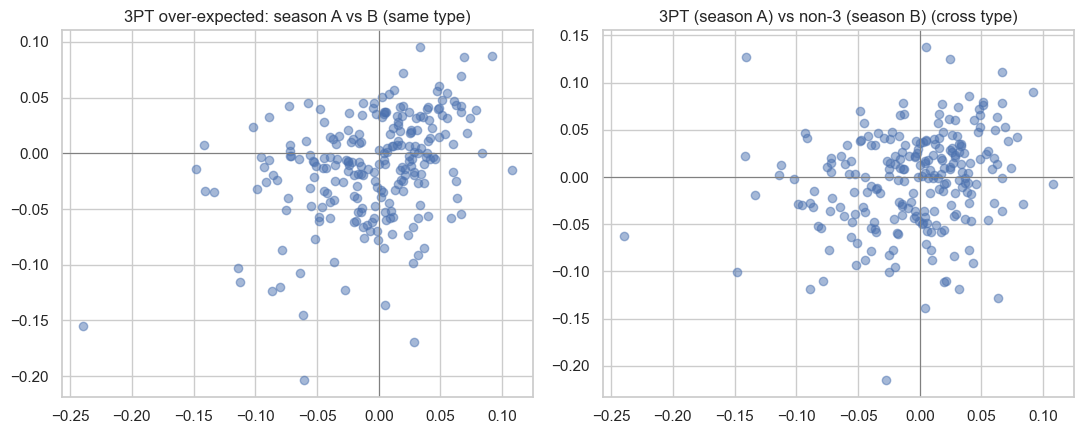

,players,Pearson r,true-effect SD,shrinkage k
defender residual (raw),321,0.3512,0.0205,523.6386
defender residual (team effect removed),321,0.3563,0.0200,549.7697


In [ ]:
#26 Player-effect persistence
res["three"] = train_c.three.values
res["def_team_id"] = train_c.def_team_id.values

MIN = 40                                           #minimum shots per cell (3PT counts are smaller, so lower than 50)
g = (res.groupby(["shooter_id", "season_id", "three"]).resid.agg(["mean", "count"])
        .unstack(["season_id", "three"]))
def col(stat, season, three): return g[(stat, season, three)]
ok = pd.Series(True, index=g.index)
for season in (s1, s2):
    for three in (0, 1):
        ok &= col("count", season, three) >= MIN     #shooter needs enough shots in ALL four cells
w = pd.DataFrame({f"{'3' if t else '2'}_{'A' if s == s1 else 'B'}": col("mean", s, t)[ok]
                  for s in (s1, s2) for t in (0, 1)})
print(f"shooters with >= {MIN} shots in every season x shot-class cell: {len(w)}")
out = pd.Series({
    "3PT season A vs 3PT season B (same type)":       w["3_A"].corr(w["3_B"]),
    "non-3 season A vs non-3 season B (same type)":   w["2_A"].corr(w["2_B"]),
    "3PT season A vs non-3 season B (cross type)":    w["3_A"].corr(w["2_B"]),
    "non-3 season A vs 3PT season B (cross type)":    w["2_A"].corr(w["3_B"]),
}, name="correlation")
display(out.round(3).to_frame())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(w["3_A"], w["3_B"], alpha=.5); axes[0].set_title("3PT over-expected: season A vs B (same type)")
axes[1].scatter(w["3_A"], w["2_B"], alpha=.5); axes[1].set_title("3PT (season A) vs non-3 (season B) (cross type)")
for ax in axes: ax.axhline(0, color="grey", lw=.8); ax.axvline(0, color="grey", lw=.8)
savefig("15_shooter_skill_dimensions")

#defender effect after removing team effect
def rel_from(resid, ids, seasons, min_n=50):
    """Season-to-season reliability of per-player mean residuals (same method as Cell 26)."""
    df = pd.DataFrame({"id": ids.values, "season": seasons.values, "r": resid.values})
    gg = df.groupby(["id", "season"]).r.agg(["mean", "count"]).unstack("season")
    a, b = gg["mean"][s1], gg["mean"][s2]
    ok_ = (gg["count"][s1] >= min_n) & (gg["count"][s2] >= min_n)
    t = pd.DataFrame({"A": a[ok_], "B": b[ok_]})
    tau2 = np.cov(t.A, t.B)[0, 1]
    return len(t), t.A.corr(t.B), np.sqrt(max(tau2, 0)), (resid.var() / tau2 if tau2 > 0 else np.inf)

team_mean = res.groupby(["def_team_id", "season_id"]).resid.transform("mean")   #defensive team's average residual per season
res["resid_team_adj"] = res.resid - team_mean
raw = rel_from(res.resid,          res.closestdef_id, res.season_id)
adj = rel_from(res.resid_team_adj, res.closestdef_id, res.season_id)
display(pd.DataFrame([raw, adj], index=["defender residual (raw)", "defender residual (team effect removed)"],
                     columns=["players", "Pearson r", "true-effect SD", "shrinkage k"]).round(4))

In [ ]:
#27 Player-effect follow-up tests
HX, HY = -41.75, 0.0

def add_features(d):
    f = d.copy()
    dx, dy = f.locationx - HX, f.locationy - HY

    #geometry
    f["angle_abs"]     = np.degrees(np.arctan2(dy.abs(), dx))   #0 deg = straight in front of the hoop, 90 = level with it, >90 = behind it
    f["dist_baseline"] = f.locationx + 47                      #feet from the baseline
    f["dist_sideline"] = 25 - f.locationy.abs()                #feet from the nearest sideline (negative = out of bounds)
    f["corner3"]       = ((f.three == 1) & (f.locationy.abs() >= 21.5) & (f.dist_baseline <= 14)).astype(int)
    f["restricted"]    = (f.distance <= 4).astype(int)         #at the rim
    f["paint"]         = ((f.locationy.abs() <= 8) & (f.dist_baseline <= 19)).astype(int)
    f["log_dist"]      = np.log1p(f.distance)                  #make rate falls fast near the rim, slowly far out
    f["dist_sq"]       = f.distance ** 2

    #defender movement over the last second
    f["gap_change_1s"]   = f.app_100 - f.closestdefdist         #ft the gap closed over the last second (+ = closing in)
    f["gap_change_last"] = f.app_025 - f.closestdefdist         #ft closed over the last quarter-second
    early = f.app_100 - f.app_050                              #ft closed in the first half of the window
    late  = f.app_050 - f.closestdefdist                       #ft closed in the last half
    f["late_minus_early"] = late - early                       #positive = closeout is speeding up (late closer)
    f["def_min_dist"]    = f[["app_100", "app_075", "app_050", "app_025", "closestdefdist"]].min(axis=1)
    f["pressure"]        = 1 / (1 + f.closestdefdist)          #steep at small distances, flat at large

    #contest structure
    dc = f[["distcont1", "distcont2", "distcont3", "distcont4"]]
    f["mean_cont"]   = dc.mean(axis=1)                         #NaN when uncontested (structural)
    f["min_cont"]    = dc.min(axis=1)
    f["n_cont_close"] = (dc <= 4).sum(axis=1)                  #contesters within 4 ft
    f["cont_gap"]    = f.distcont1 - f.closestdefdist          #how far the first contester is from the closest defender

    #shot creation/clock
    f["catch_and_shoot"] = (f.dribblesbefore == 0).astype(int)                       #no dribbles before the shot
    f["late_clock"]      = ((f.shotclock <= 4) & (f.sc_is_0 == 0)).astype(int)       #rushed shot, excluding the expired-clock spike
    return f

F_train = add_features(train_c)
F_test  = add_features(test_c)
assert list(F_test.columns) == [c for c in F_train.columns if c != "outcome"], "feature schema mismatch"
print("train features:", F_train.shape, "| test features:", F_test.shape)

train features: (425719, 68) | test features: (213977, 67)


In [ ]:
#30
EXPERIMENTS = EXPERIMENTS if "EXPERIMENTS" in globals() else []
PREDS = {}                                              #experiment name -> Series of validation predictions (indexed like F_train)
SEASONS = (s1, s2)

def season_swap(model_fn, name, feature_set, notes=""):
    """Train on one season, score the other, both directions. Logs the result and stores predictions."""
    t0, losses = time.time(), []
    pred = pd.Series(np.nan, index=F_train.index)       #every train row is validated exactly once (in its own season's fold)
    for held_out in SEASONS:
        tr = F_train[F_train.season_id != held_out]
        va = F_train[F_train.season_id == held_out]
        p = np.clip(model_fn(tr, va), 1e-4, 1 - 1e-4)   #clip: one confident miss can wreck log-loss
        pred.loc[va.index] = p
        losses.append(log_loss(va.outcome, p))
    PREDS[name] = pred
    EXPERIMENTS.append(dict(model=name, features=feature_set, validation="season-swap (2 folds)",
                            ll_hold_s1=losses[0], ll_hold_s2=losses[1], ll_mean=np.mean(losses),
                            seconds=round(time.time() - t0), notes=notes))
    return pd.DataFrame(EXPERIMENTS)

In [ ]:
#30.5 Experiment-log cleanup helper
def latest_exp():
    """Experiment log with only the most recent row for each model name."""
    return pd.DataFrame(EXPERIMENTS).drop_duplicates(subset="model", keep="last").reset_index(drop=True)

def ll(name):
    """The most recent mean log-loss logged for a given model name."""
    e = latest_exp()
    match = e.loc[e.model == name, "ll_mean"]
    assert len(match) > 0, f"No experiment logged yet with model name: {name!r}"
    return match.iloc[-1]

,model,features,validation,ll_hold_s1,ll_hold_s2,ll_mean,seconds,notes
0,constant (training make rate),none,season-swap (2 folds),0.68990,0.68938,0.68964,0,
1,logistic (simple),5 raw + 3 categoricals,season-swap (2 folds),0.64643,0.64368,0.64506,1,
2,"logistic (engineered, splines)",38 engineered + splines,season-swap (2 folds),0.63436,0.63152,0.63294,10,
3,ridge logistic C=0.001,38 engineered + splines,season-swap (2 folds),0.63495,0.63204,0.63349,5,C scored on same folds (slightly optimistic)
4,ridge logistic C=0.01,38 engineered + splines,season-swap (2 folds),0.63441,0.63172,0.63307,6,C scored on same folds (slightly optimistic)
5,ridge logistic C=0.1,38 engineered + splines,season-swap (2 folds),0.63436,0.63163,0.63299,8,C scored on same folds (slightly optimistic)
6,LASSO logistic C=0.001,38 engineered + splines,season-swap (2 folds),0.63783,0.63505,0.63644,11,C scored on same folds (slightly optimistic)
7,LASSO logistic C=0.003,38 engineered + splines,season-swap (2 folds),0.63550,0.63264,0.63407,69,C scored on same folds (slightly optimistic)
8,LASSO logistic C=0.01,38 engineered + splines,season-swap (2 folds),0.63458,0.63186,0.63322,74,C scored on same folds (slightly optimistic)
9,GBM: geometry only,12 features,season-swap (2 folds),0.64539,0.64254,0.64396,4,"LightGBM, 50% of train rows."


LASSO non-zero coefficients per fold: {'lasso0.001': [19, 24], 'lasso0.003': [33, 37], 'lasso0.01': [49, 52]}


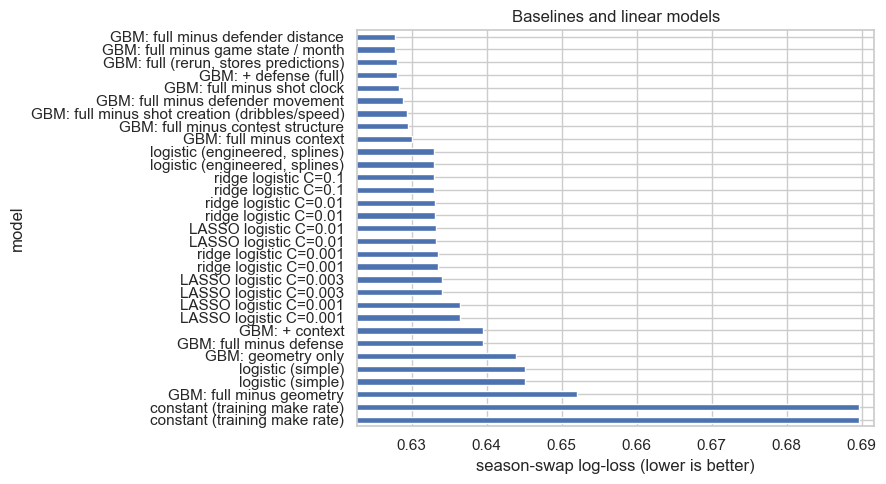

In [ ]:
#31
from sklearn.preprocessing import SplineTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression

STRUCT_ZERO = ["distcont1", "distcont2", "distcont3", "distcont4", "mean_cont", "min_cont", "cont_gap"]
SIMPLE_NUM = ["distance", "closestdefdist", "shotclock", "three", "contested"]
ENG_NUM = ["distance", "closestdefdist", "shotclock", "shooterspeed", "dribblesbefore", "three", "contested",
           "num_contesters", "log_dist", "dist_sq", "angle_abs", "dist_baseline", "dist_sideline", "corner3",
           "restricted", "paint", "gap_change_1s", "gap_change_last", "late_minus_early", "def_min_dist",
           "pressure", "n_cont_close", "mean_cont", "min_cont", "cont_gap", "catch_and_shoot", "late_clock",
           "sc_is_24", "sc_is_0", "out_of_court", "has_cont1", "has_cont2", "has_cont3", "has_cont4",
           "app_100", "app_075", "app_050", "app_025"]
CAT_COLS = ["shottype", "gamestate", "month"]
NNZ = {}                                             #records how many coefficients LASSO kept

def linear_fit_predict(tr, va, num, cats=CAT_COLS, spline_cols=(), penalty="l2", C=1.0, tag=None):
    Xtr, Xva = tr[num].copy(), va[num].copy()
    for c in num:                                                #fill and winsorize using TRAIN statistics only
        fill = 0 if c in STRUCT_ZERO else Xtr[c].median()
        Xtr[c], Xva[c] = Xtr[c].fillna(fill), Xva[c].fillna(fill)
        lo, hi = Xtr[c].quantile(.001), Xtr[c].quantile(.999)
        Xtr[c], Xva[c] = Xtr[c].clip(lo, hi), Xva[c].clip(lo, hi)
    parts_tr, parts_va = [Xtr.values.astype(float)], [Xva.values.astype(float)]
    for c in spline_cols:                                        #smooth curved effects for a linear model
        sp = SplineTransformer(n_knots=7, degree=3, extrapolation="constant").fit(Xtr[[c]])
        parts_tr.append(sp.transform(Xtr[[c]])); parts_va.append(sp.transform(Xva[[c]]))
    for c in cats:                                               #one-hot with category lists fixed in Cell 14
        parts_tr.append(pd.get_dummies(pd.Categorical(tr[c], categories=CATS[c]), drop_first=True).values.astype(float))
        parts_va.append(pd.get_dummies(pd.Categorical(va[c], categories=CATS[c]), drop_first=True).values.astype(float))
    A, B = np.hstack(parts_tr), np.hstack(parts_va)
    sc = StandardScaler().fit(A)                                 #so the penalty treats every column fairly
    solver = "lbfgs" if penalty == "l2" else "liblinear"
    m = LogisticRegression(penalty=penalty, C=C, solver=solver, max_iter=500).fit(sc.transform(A), tr.outcome.values)
    if tag: NNZ.setdefault(tag, []).append(int((m.coef_ != 0).sum()))
    return m.predict_proba(sc.transform(B))[:, 1]

season_swap(lambda tr, va: np.full(len(va), tr.outcome.mean()), "constant (training make rate)", "none")
season_swap(lambda tr, va: linear_fit_predict(tr, va, SIMPLE_NUM, C=1e6), "logistic (simple)", "5 raw + 3 categoricals")
season_swap(lambda tr, va: linear_fit_predict(tr, va, ENG_NUM, spline_cols=["distance", "closestdefdist", "shotclock"], C=1e6),
            "logistic (engineered, splines)", "38 engineered + splines")

for C in [0.001, 0.01, 0.1]:
    season_swap(lambda tr, va, C=C: linear_fit_predict(tr, va, ENG_NUM, spline_cols=["distance", "closestdefdist", "shotclock"], C=C),
                f"ridge logistic C={C}", "38 engineered + splines", notes="C scored on same folds (slightly optimistic)")
for C in [0.001, 0.003, 0.01]:
    season_swap(lambda tr, va, C=C: linear_fit_predict(tr, va, ENG_NUM, spline_cols=["distance", "closestdefdist", "shotclock"],
                                                      penalty="l1", C=C, tag=f"lasso{C}"),
                f"LASSO logistic C={C}", "38 engineered + splines", notes="C scored on same folds (slightly optimistic)")

exp = pd.DataFrame(EXPERIMENTS)
display(exp.round(5))
print("LASSO non-zero coefficients per fold:", NNZ)

ax = exp.set_index("model").ll_mean.sort_values(ascending=False).plot.barh(figsize=(9, 5))
ax.set_xlim(exp.ll_mean.min() - .005, exp.ll_mean.max() + .002)
ax.set_xlabel("season-swap log-loss (lower is better)"); ax.set_title("Baselines and linear models")
savefig("16_baselines")

In [ ]:
#32
import lightgbm as lgb

ITERS = {}                                            #best number of trees found, per model name and fold

def as_gbm(df, feats, cats):
    """Feature matrix for LightGBM; categorical columns get fixed category lists from Cell 14."""
    X = df[feats].copy()
    for c in cats:
        X[c] = pd.Categorical(X[c], categories=CATS[c])
    return X

def gbm_fit_predict(tr, va, feats, cats=(), params=None, frac=1.0, seed=SEED, tag=None):
    P = dict(objective="binary", learning_rate=0.05, num_leaves=63, min_child_samples=100,
             feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, lambda_l2=10,
             verbose=-1, seed=seed, num_threads=-1)
    P.update(params or {})
    if frac < 1:
        tr = tr.sample(frac=frac, random_state=seed)                   #optional subsample for speed
    inner = np.random.default_rng(seed).random(len(tr)) < 0.10         #10% of TRAIN rows for early stopping
    d_fit = lgb.Dataset(as_gbm(tr[~inner], feats, cats), tr.outcome.values[~inner])
    d_stop = lgb.Dataset(as_gbm(tr[inner], feats, cats), tr.outcome.values[inner])
    m = lgb.train(P, d_fit, num_boost_round=3000, valid_sets=[d_stop],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
    if tag: ITERS.setdefault(tag, []).append(m.best_iteration)
    return m.predict(as_gbm(va, feats, cats), num_iteration=m.best_iteration)


,model,features,ll_hold_s1,ll_hold_s2,ll_mean,seconds
0,"GBM: full (rerun, stores predictions)",45 features,0.62975,0.62628,0.62802,10
1,GBM: full minus defender distance,43 features,0.62971,0.62578,0.62774,7
2,GBM: full minus defender movement,37 features,0.63075,0.62693,0.62884,8
3,GBM: full minus contest structure,31 features,0.63134,0.62755,0.62944,6
4,GBM: full minus shot clock,41 features,0.63008,0.62647,0.62828,8
5,GBM: full minus shot creation (dribbles/speed),42 features,0.63136,0.62732,0.62934,8
6,GBM: full minus game state / month,43 features,0.62965,0.62594,0.62779,7
16,GBM: geometry only,12 features,0.64539,0.64254,0.64396,6
17,GBM: + context,21 features,0.64100,0.63792,0.63946,6
18,GBM: + defense (full),45 features,0.62975,0.62628,0.62802,10


best iterations (most recent run of each): {'GBM: geometry only': [76, 71], 'GBM: + context': [100, 73], 'GBM: + defense (full)': [146, 178], 'GBM: full minus geometry': [83, 76], 'GBM: full minus context': [109, 116], 'GBM: full minus defense': [100, 73]}


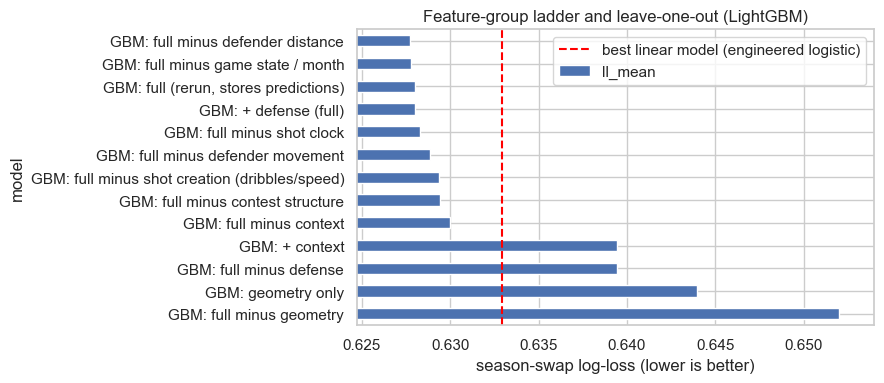

In [ ]:
#33
FRAC = 0.5
for d in (F_train, F_test):                                        #month as an ordered number (Oct=0 ... Apr=6)
    d["month_n"] = pd.Categorical(d.month, categories=["OCT", "NOV", "DEC", "JAN", "FEB", "MAR", "APR"]).codes

GEOMETRY = ["distance", "locationx", "locationy", "angle_abs", "dist_baseline", "dist_sideline",
            "three", "corner3", "restricted", "paint", "out_of_court", "shottype"]
CONTEXT  = ["gamestate", "shotclock", "sc_is_24", "sc_is_0", "late_clock", "catch_and_shoot",
            "dribblesbefore", "shooterspeed", "month_n"]
DEFENSE  = ["closestdefdist", "app_100", "app_075", "app_050", "app_025", "gap_change_1s", "gap_change_last",
            "late_minus_early", "def_min_dist", "pressure", "contested", "num_contesters",
            "distcont1", "distcont2", "distcont3", "distcont4", "has_cont1", "has_cont2", "has_cont3", "has_cont4",
            "mean_cont", "min_cont", "n_cont_close", "cont_gap"]
GBM_CATS = ["shottype", "gamestate"]                              #native categoricals in LightGBM
def cats_in(fs): return [c for c in GBM_CATS if c in fs]

def run(name, feats, notes=""):
    return season_swap(lambda tr, va: gbm_fit_predict(tr, va, feats, cats_in(feats), frac=FRAC, tag=name),
                       name, f"{len(feats)} features", notes=f"LightGBM, {int(FRAC*100)}% of train rows. {notes}")

FULL = GEOMETRY + CONTEXT + DEFENSE

# ---- add-up ladder ----
run("GBM: geometry only", GEOMETRY)
run("GBM: + context", GEOMETRY + CONTEXT)
run("GBM: + defense (full)", FULL)
# ---- leave-one-group-out ----
run("GBM: full minus geometry", CONTEXT + DEFENSE, "leave-one-out")   #note: without shot type / distance
run("GBM: full minus context",  GEOMETRY + DEFENSE, "leave-one-out")
run("GBM: full minus defense",  GEOMETRY + CONTEXT, "leave-one-out")

#display and chart
exp = latest_exp()
display(exp[exp.model.str.startswith("GBM")][["model", "features", "ll_hold_s1", "ll_hold_s2", "ll_mean", "seconds"]].round(5))
print("best iterations (most recent run of each):", {k: v[-2:] for k, v in ITERS.items()})

ref = ll("logistic (engineered, splines)")            #single number, safe even after reruns
g = exp[exp.model.str.startswith("GBM")].set_index("model").ll_mean
ax = g.sort_values(ascending=False).plot.barh(figsize=(9, 4))
ax.axvline(ref, color="red", ls="--", label="best linear model (engineered logistic)")
ax.set_xlim(g.min() - .003, max(g.max(), ref) + .002); ax.legend()
ax.set_xlabel("season-swap log-loss (lower is better)"); ax.set_title("Feature-group ladder and leave-one-out (LightGBM)")
savefig("17_feature_group_ladder")

,cost of removing (log-loss)
defender distance,-0.00027
game state / month,-0.00022
shot clock,0.00026
defender movement,0.00082
shot creation (dribbles/speed),0.00132
contest structure,0.00143


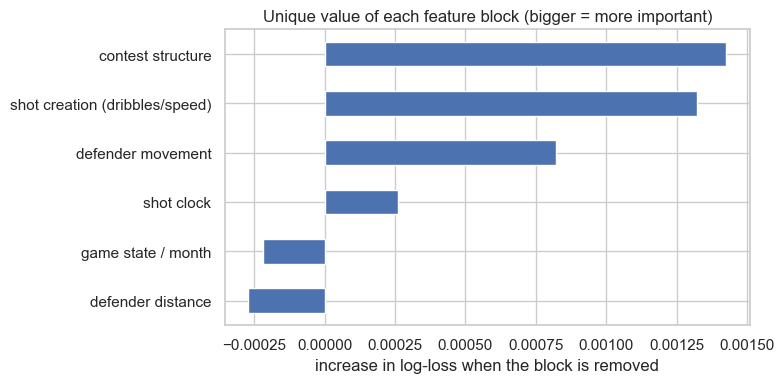

In [ ]:
#34

DEF_DIST    = ["closestdefdist", "pressure"]
DEF_MOVE    = ["app_100", "app_075", "app_050", "app_025", "gap_change_1s", "gap_change_last",
               "late_minus_early", "def_min_dist"]
DEF_CONTEST = ["contested", "num_contesters", "distcont1", "distcont2", "distcont3", "distcont4",
               "has_cont1", "has_cont2", "has_cont3", "has_cont4", "mean_cont", "min_cont", "n_cont_close", "cont_gap"]
CTX_CLOCK   = ["shotclock", "sc_is_24", "sc_is_0", "late_clock"]
CTX_CREATE  = ["catch_and_shoot", "dribblesbefore", "shooterspeed"]
CTX_STATE   = ["gamestate", "month_n"]

FULL = GEOMETRY + CONTEXT + DEFENSE
assert set(FULL) == set(DEF_DIST + DEF_MOVE + DEF_CONTEST + CTX_CLOCK + CTX_CREATE + CTX_STATE + GEOMETRY), "block lists do not cover the full set"

run("GBM: full (rerun, stores predictions)", FULL)
blocks = {"defender distance": DEF_DIST, "defender movement": DEF_MOVE, "contest structure": DEF_CONTEST,
          "shot clock": CTX_CLOCK, "shot creation (dribbles/speed)": CTX_CREATE, "game state / month": CTX_STATE}
for label, cols in blocks.items():
    run(f"GBM: full minus {label}", [c for c in FULL if c not in cols], "block leave-one-out")

#cost of removing each block
full_ll = ll("GBM: full (rerun, stores predictions)")
cost = pd.Series({label: ll(f"GBM: full minus {label}") - full_ll for label in blocks},
                 name="cost of removing (log-loss)").sort_values()
display(cost.round(5).to_frame())

ax = cost.plot.barh(figsize=(8, 4)); ax.set_xlabel("increase in log-loss when the block is removed")
ax.set_title("Unique value of each feature block (bigger = more important)")
savefig("18_block_ablation")

In [ ]:
#35
FRAC = 1.0                                             #full data for the final-quality numbers
configs = {
    "default 63 leaves":                     dict(num_leaves=63, min_child_samples=100, lambda_l2=10),
    "31 leaves, min leaf 200":               dict(num_leaves=31, min_child_samples=200, lambda_l2=10),
    "15 leaves, min leaf 200":               dict(num_leaves=15, min_child_samples=200, lambda_l2=10),
    "31 leaves, min leaf 500, L2=30":        dict(num_leaves=31, min_child_samples=500, lambda_l2=30),
    "15 leaves, min leaf 300, lr .03, ff .6": dict(num_leaves=15, min_child_samples=300, lambda_l2=10, learning_rate=0.03, feature_fraction=0.6),
    "63 leaves, min leaf 300, L2=50, lr .03": dict(num_leaves=63, min_child_samples=300, lambda_l2=50, learning_rate=0.03),
}
cfg_rows = []
for label, prm in configs.items():
    name = f"GBM grid: {label}"
    season_swap(lambda tr, va, prm=prm, name=name: gbm_fit_predict(tr, va, FULL, cats_in(FULL), params=prm, frac=FRAC, tag=name),
                name, f"{len(FULL)} features", notes="grid on same folds (slightly optimistic); all rows")
    cfg_rows.append((label, ll(name), ITERS[name][-2:]))

grid = pd.DataFrame(cfg_rows, columns=["config", "ll_mean", "best_iters (per fold)"]).sort_values("ll_mean")
display(grid.round(5))

BEST_LABEL = grid.iloc[0].config                       #remembered for the next steps
BEST_PARAMS = configs[BEST_LABEL]
print("best config:", BEST_LABEL, BEST_PARAMS)

,config,ll_mean,best_iters (per fold)
5,"63 leaves, min leaf 300, L2=50, lr .03",0.62641,"[276, 346]"
1,"31 leaves, min leaf 200",0.62641,"[219, 375]"
0,default 63 leaves,0.62644,"[186, 129]"
4,"15 leaves, min leaf 300, lr .03, ff .6",0.62651,"[716, 953]"
3,"31 leaves, min leaf 500, L2=30",0.62659,"[183, 333]"
2,"15 leaves, min leaf 200",0.62660,"[419, 598]"


best config: 63 leaves, min leaf 300, L2=50, lr .03 {'num_leaves': 63, 'min_child_samples': 300, 'lambda_l2': 50, 'learning_rate': 0.03}


In [ ]:
#36
needed = ["season_swap", "PREDS", "linear_fit_predict", "ENG_NUM", "gbm_fit_predict", "cats_in",
          "FULL", "BEST_PARAMS", "BEST_LABEL", "latest_exp", "ll"]
missing = [n for n in needed if n not in globals()]
assert not missing, f"Run these first (they define: {missing}). Cell 30/30b -> PREDS/season_swap/latest_exp/ll; Cell 31 -> linear_fit_predict/ENG_NUM; Cell 32 -> gbm_fit_predict; Cell 33 -> FULL/cats_in; Cell 35 -> BEST_PARAMS/BEST_LABEL."
assert "pgame" in F_train.columns, "F_train has no 'pgame' column (created in Cell 18 before Cell 21 runs clean)"

SPLINES = ["distance", "closestdefdist", "shotclock"]        #same spline columns used in Cell 31

#Rerun the two models once so their per-shot predictions are stored in PREDS (dict keys overwrite cleanly,
#so re-running this is always safe, unlike the EXPERIMENTS log).
season_swap(lambda tr, va: linear_fit_predict(tr, va, ENG_NUM, spline_cols=SPLINES, C=1e6),
            "logistic (engineered) [preds stored]", "38 engineered + splines")
season_swap(lambda tr, va: gbm_fit_predict(tr, va, FULL, cats_in(FULL), params=BEST_PARAMS, frac=1.0, tag="best"),
            "GBM tuned (best config, all rows)", f"{len(FULL)} features", notes=f"config: {BEST_LABEL} (picked on same folds)")

yv = F_train.outcome.values
def shot_loss(name):
    """Per-shot log-loss of a stored model."""
    p = PREDS[name].values
    return -(yv * np.log(p) + (1 - yv) * np.log(1 - p))

def paired_diff(a, b):
    """Mean of loss_a - loss_b with a cluster-robust 95% CI (clusters = proxy games)."""
    d = shot_loss(a) - shot_loss(b)
    df_ = pd.DataFrame({"g": F_train.pgame.values, "d": d}).groupby("g").d.agg(["sum", "count"])
    N, G = df_["count"].sum(), len(df_)
    m = df_["sum"].sum() / N
    se = np.sqrt(((df_["sum"] - m * df_["count"]) ** 2).sum()) / N * np.sqrt(G / (G - 1))
    return m, m - 1.96 * se, m + 1.96 * se

pairs = [("GBM tuned (best config, all rows)", "logistic (engineered) [preds stored]"),
         ("GBM tuned (best config, all rows)", "GBM: full (rerun, stores predictions)"),
         ("GBM: full (rerun, stores predictions)", "GBM: full minus defender movement"),
         ("GBM: full (rerun, stores predictions)", "GBM: full minus contest structure"),
         ("GBM: full (rerun, stores predictions)", "GBM: full minus shot clock")]
rows = []
for a, b in pairs:
    if a in PREDS and b in PREDS:
        m, lo, hi = paired_diff(a, b)
        rows.append(dict(model_A=a, model_B=b, mean_diff=m, ci_low=lo, ci_high=hi, A_better_significantly=(hi < 0)))
    else:
        print("skipped (predictions not stored):", a, "vs", b)
display(pd.DataFrame(rows).round(5))

,model_A,model_B,mean_diff,ci_low,ci_high,A_better_significantly
0,"GBM tuned (best config, all rows)",logistic (engineered) [preds stored],-0.00653,-0.00690,-0.00616,True
1,"GBM tuned (best config, all rows)","GBM: full (rerun, stores predictions)",-0.00161,-0.00182,-0.00140,True
2,"GBM: full (rerun, stores predictions)",GBM: full minus defender movement,-0.00082,-0.00106,-0.00059,True
3,"GBM: full (rerun, stores predictions)",GBM: full minus contest structure,-0.00143,-0.00167,-0.00119,True
4,"GBM: full (rerun, stores predictions)",GBM: full minus shot clock,-0.00026,-0.00045,-0.00007,True


In [ ]:
#37 with leak adjustment
K_SHOOTER, K_DEFENDER = 246, 524          # from Cell 26's cross-season reliability estimates

def player_effects(tr, base_feats, base_cats, k_shooter=K_SHOOTER, k_defender=K_DEFENDER, seed=SEED):
    """Fit a fast context-only GBM on `tr` with 5-fold CV (fixed 200 rounds -- this is only a residual
    generator, not the final predictor). Returns FOUR things:
      shooter_eff_full, def_eff_full   : shrunk lookup tables (id -> effect) built from ALL of `tr`.
        Safe to map onto rows that are NOT in `tr` (a validation/test season), since those rows never
        contributed to the table.
      shooter_eff_train, def_eff_train : pd.Series aligned to tr.index giving each of tr's OWN rows a
        cross-fitted, leakage-free effect -- built from the OTHER 4 folds only, never the row's own fold.
    """
    Xc = as_gbm(tr, base_feats, base_cats)
    y = tr.outcome.values
    oof = np.zeros(len(tr))
    fold_id = np.zeros(len(tr), dtype=int)
    for i, (tr_i, va_i) in enumerate(KFold(5, shuffle=True, random_state=seed).split(Xc)):
        P = dict(objective="binary", learning_rate=0.05, num_leaves=63, min_child_samples=100,
                 feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, lambda_l2=10,
                 verbose=-1, seed=seed, num_threads=-1)
        m = lgb.train(P, lgb.Dataset(Xc.iloc[tr_i], y[tr_i]), num_boost_round=200)
        oof[va_i] = m.predict(Xc.iloc[va_i])
        fold_id[va_i] = i
    resid = y - oof

    def shrunk_table(ids, resid_vals, k):
        g = pd.Series(resid_vals).groupby(ids).agg(["mean", "count"])
        return g["count"] / (g["count"] + k) * g["mean"]          # shrink toward 0 (the residual's own center)

    #full-tr tables: only ever mapped onto rows OUTSIDE tr (validation/test season)
    shooter_eff_full = shrunk_table(tr.shooter_id.values, resid, k_shooter)
    def_eff_full = shrunk_table(tr.closestdef_id.values, resid, k_defender)

    #cross-fitted, leakage-free per-row effects for tr's OWN rows
    shooter_eff_train = pd.Series(0.0, index=tr.index)
    def_eff_train = pd.Series(0.0, index=tr.index)
    for i in range(5):
        other, this_fold = fold_id != i, fold_id == i
        sh_tab = shrunk_table(tr.shooter_id.values[other], resid[other], k_shooter)
        df_tab = shrunk_table(tr.closestdef_id.values[other], resid[other], k_defender)
        idx = tr.index[this_fold]
        shooter_eff_train.loc[idx] = tr.loc[idx, "shooter_id"].map(sh_tab).fillna(0.0)
        def_eff_train.loc[idx] = tr.loc[idx, "closestdef_id"].map(df_tab).fillna(0.0)

    return shooter_eff_full, def_eff_full, shooter_eff_train, def_eff_train

def add_player_effects(tr, va, shooter_eff_full, def_eff_full, shooter_eff_train, def_eff_train):
    """Join the shrunk effects onto tr and va as two new numeric columns.
       tr gets its pre-computed CROSS-FITTED per-row effects (leakage-free: no row's own residual
       informed its own value). va gets the FULL-tr lookup table (fine: va rows were never part of that
       table). Unseen players -> 0."""
    tr2 = tr.assign(shooter_eff=shooter_eff_train.reindex(tr.index).values,
                    def_eff=def_eff_train.reindex(tr.index).values)
    va2 = va.assign(shooter_eff=va.shooter_id.map(shooter_eff_full).fillna(0.0),
                    def_eff=va.closestdef_id.map(def_eff_full).fillna(0.0))
    return tr2, va2

In [ ]:
#38
FULL_PLUS_PLAYERS = FULL + ["shooter_eff", "def_eff"]

def gbm_with_players(tr, va):
    sh_full, df_full, sh_tr, df_tr = player_effects(tr, FULL, cats_in(FULL))
    tr2, va2 = add_player_effects(tr, va, sh_full, df_full, sh_tr, df_tr)
    return gbm_fit_predict(tr2, va2, FULL_PLUS_PLAYERS, cats_in(FULL_PLUS_PLAYERS), params=BEST_PARAMS,
                           frac=1.0, tag="gbm_players")

season_swap(gbm_with_players, "GBM tuned + shrunk player effects", f"{len(FULL_PLUS_PLAYERS)} features",
           notes=f"player effects fit per-fold on training season only; k_shooter={K_SHOOTER}, k_defender={K_DEFENDER}")

exp = latest_exp()
display(exp[exp.model.str.contains("GBM tuned")][["model", "features", "ll_hold_s1", "ll_hold_s2", "ll_mean", "seconds", "notes"]])

# paired comparison against the best model WITHOUT player effects, on the same shots
m, lo, hi = paired_diff("GBM tuned + shrunk player effects", "GBM tuned (best config, all rows)")
print(f"player effects vs no player effects: mean diff = {m:.5f}  95% CI [{lo:.5f}, {hi:.5f}]  "
      f"{'SIGNIFICANT improvement' if hi < 0 else ('no significant difference' if lo <= 0 <= hi else 'SIGNIFICANTLY WORSE')}")

,model,features,ll_hold_s1,ll_hold_s2,ll_mean,seconds,notes
29,"GBM tuned (best config, all rows)",45 features,0.628217,0.624600,0.626408,16,"config: 63 leaves, min leaf 300, L2=50, lr .03..."
35,GBM tuned + shrunk player effects,47 features,0.626712,0.622862,0.624787,68,player effects fit per-fold on training season...


player effects vs no player effects: mean diff = -0.00162  95% CI [-0.00187, -0.00138]  SIGNIFICANT improvement


Expected Calibration Error (20 bins, weighted): 0.0071
Brier score: 0.21909   |   log-loss: 0.62478


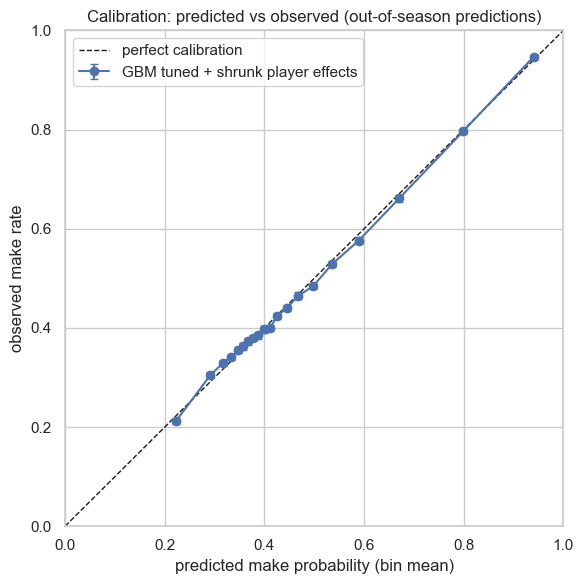

,pred,k,n,obs,h
bin,,,,,
"(0.046, 0.272]",0.2226,4518,21286,0.2123,0.0055
"(0.272, 0.306]",0.2913,6477,21286,0.3043,0.0062
"(0.306, 0.326]",0.3168,7012,21286,0.3294,0.0063
"(0.326, 0.34]",0.3332,7265,21286,0.3413,0.0064
"(0.34, 0.352]",0.3462,7551,21286,0.3548,0.0064
"(0.352, 0.362]",0.3573,7721,21286,0.3628,0.0065
"(0.362, 0.372]",0.3674,7933,21286,0.3727,0.0065
"(0.372, 0.382]",0.3771,8068,21286,0.3791,0.0065
"(0.382, 0.393]",0.3872,8189,21286,0.3847,0.0065



By shot type:


,n,pred,obs,gap
shottype,,,,
dunk,25767.0,0.8869,0.8854,0.0016
floater,27700.0,0.4150,0.4169,-0.0018
heave,1118.0,0.1738,0.0948,0.0790
jumper,231542.0,0.3781,0.3781,-0.0000
layup,115446.0,0.5378,0.5352,0.0026
post,14774.0,0.4497,0.4537,-0.0040
tip,9372.0,0.4908,0.4812,0.0095



By distance band:


,n,pred,obs,gap
distance,,,,
"(0, 4]",101291.0,0.6686,0.6659,0.0027
"(4, 10]",77313.0,0.4401,0.4397,0.0003
"(10, 16]",43136.0,0.4357,0.4370,-0.0013
"(16, 22]",24191.0,0.4040,0.4069,-0.0028
"(22, 24]",47140.0,0.3888,0.3848,0.0040
"(24, 30]",129091.0,0.3558,0.3562,-0.0003
"(30, 100]",3557.0,0.2369,0.2120,0.0249


In [ ]:
#39
BEST_MODEL = "GBM tuned + shrunk player effects"
p_all = PREDS[BEST_MODEL].values
y_all2 = F_train.outcome.values

def reliability_table(p, y, q=20):
    b = pd.qcut(pd.Series(p), q, duplicates="drop")
    g = pd.DataFrame({"bin": b, "p": p, "y": y}).groupby("bin", observed=True).agg(
        pred=("p", "mean"), k=("y", "sum"), n=("y", "size"))
    g["obs"], g["h"] = wilson(g.k, g.n)          #wilson() defined in Cell 23
    return g

rel = reliability_table(p_all, y_all2)
ece = (rel.n / rel.n.sum() * (rel.pred - rel.obs).abs()).sum()    #expected calibration error
print(f"Expected Calibration Error (20 bins, weighted): {ece:.4f}")
print(f"Brier score: {np.mean((p_all - y_all2) ** 2):.5f}   |   log-loss: {log_loss(y_all2, np.clip(p_all, 1e-4, 1-1e-4)):.5f}")

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
ax.errorbar(rel.pred, rel.obs, yerr=rel.h, marker="o", capsize=3, label=BEST_MODEL)
ax.set_xlabel("predicted make probability (bin mean)"); ax.set_ylabel("observed make rate")
ax.set_title("Calibration: predicted vs observed (out-of-season predictions)")
ax.legend(); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
savefig("19_calibration_overall")
display(rel.round(4))

#calibration within important subgroups
def subgroup_calibration(col, bins=None):
    g = F_train[[col]].copy(); g["p"] = p_all; g["y"] = y_all2
    if bins is not None:
        g[col] = pd.cut(g[col], bins)
    return g.groupby(col, observed=True).apply(lambda d: pd.Series({
        "n": len(d), "pred": d.p.mean(), "obs": d.y.mean(), "gap": d.p.mean() - d.y.mean()}))

print("\nBy shot type:"); display(subgroup_calibration("shottype").round(4))
print("\nBy distance band:"); display(subgroup_calibration("distance", bins=[0, 4, 10, 16, 22, 24, 30, 100]).round(4))

In [ ]:
#40 Calibration method comparison
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression as LR

def eval_calibrators(p, y, seed=SEED, n_splits=4):
    """Average, over n_splits random halves, the log-loss of: raw / Platt-scaled / isotonic-scaled
    predictions, always fitting the calibrator on one half and scoring on the other (both directions)."""
    rows = []
    rng_ = np.random.default_rng(seed)
    for rep in range(n_splits):
        idx = rng_.permutation(len(p))
        half = len(idx) // 2
        for fit_idx, ev_idx in [(idx[:half], idx[half:]), (idx[half:], idx[:half])]:
            p_fit, y_fit = p[fit_idx], y[fit_idx]
            p_ev, y_ev = p[ev_idx], y[ev_idx]
            raw_ll = log_loss(y_ev, np.clip(p_ev, 1e-4, 1 - 1e-4))

            logit_fit = np.log(np.clip(p_fit, 1e-4, 1 - 1e-4) / (1 - np.clip(p_fit, 1e-4, 1 - 1e-4)))
            logit_ev  = np.log(np.clip(p_ev,  1e-4, 1 - 1e-4) / (1 - np.clip(p_ev,  1e-4, 1 - 1e-4)))
            platt = LR().fit(logit_fit.reshape(-1, 1), y_fit)
            platt_ll = log_loss(y_ev, np.clip(platt.predict_proba(logit_ev.reshape(-1, 1))[:, 1], 1e-4, 1 - 1e-4))

            iso = IsotonicRegression(out_of_bounds="clip").fit(p_fit, y_fit)
            iso_ll = log_loss(y_ev, np.clip(iso.predict(p_ev), 1e-4, 1 - 1e-4))

            rows.append(dict(raw=raw_ll, platt=platt_ll, isotonic=iso_ll))
    return pd.DataFrame(rows)

calib_test = eval_calibrators(p_all, y_all2)
display(calib_test.mean().to_frame("mean log-loss").round(5))
display((calib_test.mean() - calib_test["raw"].mean()).to_frame("vs raw (negative = improvement)").round(5))

,mean log-loss
raw,0.62588
platt,0.62569
isotonic,0.62530


,vs raw (negative = improvement)
raw,0.00000
platt,-0.00018
isotonic,-0.00057


In [ ]:
#41 Final ensemble calibration
class IdentityCalibrator:
    """No calibration -- used when nothing beat raw on held-out log-loss."""
    def predict(self, p):
        return np.asarray(p)

class PlattCalibrator:
    def __init__(self, model):
        self.model = model
    def predict(self, p):
        p = np.clip(np.asarray(p), 1e-4, 1 - 1e-4)
        logit = np.log(p / (1 - p))
        return self.model.predict_proba(logit.reshape(-1, 1))[:, 1]

ENSEMBLE_MODELS = ["GBM tuned + shrunk player effects",
                   "CatBoost (our features + our shrunk effects)",
                   "XGBoost (our features + our shrunk effects)"]

p_ens_oos = np.mean(np.column_stack([PREDS[m].values for m in ENSEMBLE_MODELS]), axis=1)
y_ens_oos = F_train.outcome.values

print("equal-weight ensemble OOS log-loss (raw):",
      round(log_loss(y_ens_oos, np.clip(p_ens_oos, 1e-4, 1 - 1e-4)), 5))

calib_test_ens = eval_calibrators(p_ens_oos, y_ens_oos)          #eval_calibrators() defined in Cell 40
display(calib_test_ens.mean().to_frame("mean log-loss").round(5))
display((calib_test_ens.mean() - calib_test_ens["raw"].mean()).to_frame("vs raw (negative = improvement)").round(5))

BEST_CALIB = calib_test_ens.mean().idxmin()
print(f"selected calibration for the ensemble: {BEST_CALIB}")

if BEST_CALIB == "raw":
    FINAL_CALIBRATOR = IdentityCalibrator()
elif BEST_CALIB == "platt":
    logit_all = np.log(np.clip(p_ens_oos, 1e-4, 1 - 1e-4) / (1 - np.clip(p_ens_oos, 1e-4, 1 - 1e-4)))
    FINAL_CALIBRATOR = PlattCalibrator(LR().fit(logit_all.reshape(-1, 1), y_ens_oos))
else:  # "isotonic"
    FINAL_CALIBRATOR = IsotonicRegression(out_of_bounds="clip").fit(p_ens_oos, y_ens_oos)

calibrated_ens_oos = FINAL_CALIBRATOR.predict(p_ens_oos)
print("ensemble OOS log-loss after selected calibration:",
      round(log_loss(y_ens_oos, np.clip(calibrated_ens_oos, 1e-4, 1 - 1e-4)), 5))

equal-weight ensemble OOS log-loss (raw): 0.62429


,mean log-loss
raw,0.62429
platt,0.62429
isotonic,0.62423


,vs raw (negative = improvement)
raw,0.00000
platt,0.00000
isotonic,-0.00006


selected calibration for the ensemble: isotonic
ensemble OOS log-loss after selected calibration: 0.62381


In [ ]:
#42 Final model training and submission
ITERS["gbm_players"] = ITERS["gbm_players"][-2:]
ITERS["catboost_a"] = ITERS["catboost_a"][-2:]
ITERS["xgb_a"] = ITERS["xgb_a"][-2:]

print("building final shrunk player effects from ALL training data...")
FINAL_SHOOTER_EFF, FINAL_DEF_EFF, FINAL_SHOOTER_EFF_TRAIN, FINAL_DEF_EFF_TRAIN = player_effects(F_train, FULL, cats_in(FULL))

F_train_final = F_train.assign(
    shooter_eff=FINAL_SHOOTER_EFF_TRAIN.reindex(F_train.index).values,
    def_eff=FINAL_DEF_EFF_TRAIN.reindex(F_train.index).values)
F_test_final = F_test.assign(
    shooter_eff=F_test.shooter_id.map(FINAL_SHOOTER_EFF).fillna(0.0),
    def_eff=F_test.closestdef_id.map(FINAL_DEF_EFF).fillna(0.0))

unseen_sh = (~F_test.shooter_id.isin(FINAL_SHOOTER_EFF.index)).mean()
unseen_df = (~F_test.closestdef_id.isin(FINAL_DEF_EFF.index)).mean()
print(f"test shots with an unseen shooter: {unseen_sh:.2%} (effect=0) | unseen defender: {unseen_df:.2%} (effect=0)")

y_final = F_train_final.outcome.values
X_final_lgb = as_gbm(F_train_final, FULL_PLUS_PLAYERS, cats_in(FULL_PLUS_PLAYERS))
X_test_lgb = as_gbm(F_test_final, FULL_PLUS_PLAYERS, cats_in(FULL_PLUS_PLAYERS))

#LightGBM: own final round count, from its own season-swap best iterations (Cell 38, tag "gbm_players")
LGBM_ROUNDS = int(np.median(ITERS["gbm_players"]))
print(f"LightGBM final rounds: median of {ITERS['gbm_players']} = {LGBM_ROUNDS}")
P_lgbm_final = dict(objective="binary", learning_rate=0.05, num_leaves=63, min_child_samples=100,
                    feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, lambda_l2=10,
                    verbose=-1, seed=SEED, num_threads=-1)
P_lgbm_final.update(BEST_PARAMS)
LGBM_FINAL_MODEL = lgb.train(P_lgbm_final, lgb.Dataset(X_final_lgb, y_final), num_boost_round=LGBM_ROUNDS)
raw_test_lgbm = LGBM_FINAL_MODEL.predict(X_test_lgb)

#CatBoost: own final iteration count, from its own season-swap best iterations
CAT_ROUNDS = int(np.median(ITERS["catboost_a"]))
print(f"CatBoost final iterations: median of {ITERS['catboost_a']} = {CAT_ROUNDS}")
P_cat_final = dict(loss_function="Logloss", learning_rate=0.05, depth=6, l2_leaf_reg=10,
                   random_seed=SEED, verbose=False, allow_writing_files=False, iterations=CAT_ROUNDS)
CAT_FINAL_MODEL = CatBoostClassifier(**P_cat_final)
CAT_FINAL_MODEL.fit(F_train_final[FULL_PLUS_PLAYERS], y_final, cat_features=cats_in(FULL_PLUS_PLAYERS))
raw_test_cat = CAT_FINAL_MODEL.predict_proba(F_test_final[FULL_PLUS_PLAYERS])[:, 1]

#XGBoost: own final round count, from its own season-swap best_iteration
#      +1 because best_iteration is the zero-indexed ROUND at which the best score occurred ----
XGB_ROUNDS = int(np.median(ITERS["xgb_a"])) + 1
print(f"XGBoost final rounds: median of {ITERS['xgb_a']} + 1 = {XGB_ROUNDS}")
P_xgb_final = dict(objective="binary:logistic", max_depth=6, learning_rate=0.05, reg_lambda=10,
                   subsample=0.8, colsample_bytree=0.8, tree_method="hist", enable_categorical=True,
                   random_state=SEED, n_estimators=XGB_ROUNDS)
XGB_FINAL_MODEL = xgb.XGBClassifier(**P_xgb_final)
XGB_FINAL_MODEL.fit(as_xgb(F_train_final, FULL_PLUS_PLAYERS, cats_in(FULL_PLUS_PLAYERS)), y_final)
raw_test_xgb = XGB_FINAL_MODEL.predict_proba(as_xgb(F_test_final, FULL_PLUS_PLAYERS, cats_in(FULL_PLUS_PLAYERS)))[:, 1]

#equal-weight ensemble
raw_test_pred = (raw_test_lgbm + raw_test_cat + raw_test_xgb) / 3
calibrated_test_pred = FINAL_CALIBRATOR.predict(raw_test_pred)          # FINAL_CALIBRATOR selected in Cell 41

print("raw ensemble test prediction stats:", pd.Series(raw_test_pred).describe().round(4).to_dict())
print("calibrated ensemble test prediction stats:", pd.Series(calibrated_test_pred).describe().round(4).to_dict())

sub_final = sub.copy()                              #template from Cell 3
sub_final["make_prob"] = np.clip(calibrated_test_pred, 1e-4, 1 - 1e-4)
sub_final.to_csv("submission.csv", index=False)
print("submission.csv written:", sub_final.shape)
sub_final.head()

building final shrunk player effects from ALL training data...
test shots with an unseen shooter: 0.54% (effect=0) | unseen defender: 0.76% (effect=0)
LightGBM final rounds: median of [292, 331] = 311
CatBoost final iterations: median of [904, 902] = 903
XGBoost final rounds: median of [210, 342] + 1 = 277
raw ensemble test prediction stats: {'count': 213977.0, 'mean': 0.4569, 'std': 0.1746, 'min': 0.0339, '25%': 0.3506, '50%': 0.4039, '75%': 0.5119, 'max': 0.9914}
calibrated ensemble test prediction stats: {'count': 213977.0, 'mean': 0.456, 'std': 0.175, 'min': 0.0908, '25%': 0.3563, '50%': 0.396, '75%': 0.5054, 'max': 1.0}
submission.csv written: (213977, 2)


,shot_id,make_prob
0,1,0.380856
1,5,0.572003
2,6,0.474958
3,8,0.443498
4,10,0.383517


In [ ]:
#43 Final overfitting check
in_sample_lgbm = LGBM_FINAL_MODEL.predict(X_final_lgb)
in_sample_cat = CAT_FINAL_MODEL.predict_proba(F_train_final[FULL_PLUS_PLAYERS])[:, 1]
in_sample_xgb = XGB_FINAL_MODEL.predict_proba(as_xgb(F_train_final, FULL_PLUS_PLAYERS, cats_in(FULL_PLUS_PLAYERS)))[:, 1]
in_sample_ens = (in_sample_lgbm + in_sample_cat + in_sample_xgb) / 3
in_sample_ll = log_loss(y_final, np.clip(in_sample_ens, 1e-4, 1 - 1e-4))

oos_ll = log_loss(y_ens_oos, np.clip(p_ens_oos, 1e-4, 1 - 1e-4))            #from Cell 41

print(f"in-sample (train, same rows each final model was fit on):  {in_sample_ll:.5f}")
print(f"out-of-season (season-swap PREDS averaged, Cell 41):        {oos_ll:.5f}")
print(f"gap (in-sample vs out-of-season): {oos_ll - in_sample_ll:.5f}  "
      f"(expected: in-sample uses 100% of data, out-of-season uses ~50% per season-swap fold)")

in-sample (train, same rows each final model was fit on):  0.61281
out-of-season (season-swap PREDS averaged, Cell 41):        0.62429
gap (in-sample vs out-of-season): 0.01148  (expected: in-sample uses 100% of data, out-of-season uses ~50% per season-swap fold)


In [ ]:
#44 CatBoost comparison
try:
    from catboost import CatBoostClassifier
except ImportError:
    import sys, subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "catboost", "-q"])
    from catboost import CatBoostClassifier

def with_player_effects(fit_predict_fn):
    """Wraps a (tr, va, feats, cat_feats, **kwargs) -> predictions function so shooter_eff/def_eff are
    computed fresh from tr (the current training fold only) and joined onto both tr and va before the
    wrapped function runs -- the same leakage-safe, cross-fitted pattern Cell 38 used for LightGBM
    (gbm_with_players), factored out here so it isn't accidentally skipped by a new model."""
    def wrapped(tr, va, feats, cat_feats, **kwargs):
        sh_full, df_full, sh_tr, df_tr = player_effects(tr, FULL, cats_in(FULL))
        tr2, va2 = add_player_effects(tr, va, sh_full, df_full, sh_tr, df_tr)
        return fit_predict_fn(tr2, va2, feats, cat_feats, **kwargs)
    return wrapped

def catboost_fit_predict(tr, va, feats, cat_feats, params=None, tag=None):
    P = dict(loss_function="Logloss", eval_metric="Logloss", iterations=3000, learning_rate=0.05,
             depth=6, l2_leaf_reg=10, random_seed=SEED, verbose=False, early_stopping_rounds=100,
             allow_writing_files=False)
    P.update(params or {})
    inner = np.random.default_rng(SEED).random(len(tr)) < 0.10        # same 10%-of-train early-stop rule as LightGBM
    Xtr, Xst = tr.loc[~inner, feats], tr.loc[inner, feats]
    ytr, yst = tr.outcome.values[~inner], tr.outcome.values[inner]
    m = CatBoostClassifier(**P)
    m.fit(Xtr, ytr, cat_features=cat_feats, eval_set=(Xst, yst), use_best_model=True)
    if tag: ITERS.setdefault(tag, []).append(m.get_best_iteration())
    return m.predict_proba(va[feats])[:, 1]

catboost_with_players = with_player_effects(catboost_fit_predict)

#same feature set as tuned LightGBM
season_swap(lambda tr, va: catboost_with_players(tr, va, FULL_PLUS_PLAYERS, cats_in(FULL_PLUS_PLAYERS), tag="catboost_a"),
           "CatBoost (our features + our shrunk effects)", f"{len(FULL_PLUS_PLAYERS)} features")

#raw player/team IDs
RAW_ID_COLS = ["shooter_id", "closestdef_id", "off_team_id", "def_team_id"]
FULL_PLUS_RAW_IDS = FULL + RAW_ID_COLS
season_swap(lambda tr, va: catboost_fit_predict(tr, va, FULL_PLUS_RAW_IDS, cats_in(FULL) + RAW_ID_COLS, tag="catboost_b"),
           "CatBoost (raw player/team IDs, native encoding)", f"{len(FULL_PLUS_RAW_IDS)} features")

exp = latest_exp()
display(exp[exp.model.str.startswith("CatBoost")][["model", "features", "ll_hold_s1", "ll_hold_s2", "ll_mean", "seconds"]].round(5))
print("CatBoost best iterations:", {k: v[-2:] for k, v in ITERS.items() if k.startswith("catboost")})

,model,features,ll_hold_s1,ll_hold_s2,ll_mean,seconds
34,CatBoost (our features + our shrunk effects),47 features,0.62647,0.62326,0.62487,314
35,"CatBoost (raw player/team IDs, native encoding)",49 features,0.62777,0.62633,0.62705,790


CatBoost best iterations: {'catboost_a': [904, 902], 'catboost_b': [1176, 1504]}


In [ ]:
#45 XGBoost comparison
try:
    import xgboost as xgb
except ImportError:
    import sys, subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "xgboost", "-q"])
    import xgboost as xgb
print("xgboost version:", xgb.__version__)

def as_xgb(df, feats, cats):
    """Feature frame for XGBoost's native categorical support: categorical columns as pandas 'category' dtype."""
    X = df[feats].copy()
    for c in cats:
        X[c] = pd.Categorical(X[c], categories=CATS[c] if c in CATS else sorted(df[c].unique()))
    return X

def xgb_fit_predict(tr, va, feats, cat_feats, params=None, tag=None):
    P = dict(objective="binary:logistic", eval_metric="logloss", max_depth=6, learning_rate=0.05,
             reg_lambda=10, subsample=0.8, colsample_bytree=0.8, tree_method="hist",
             enable_categorical=True, random_state=SEED, n_estimators=3000, early_stopping_rounds=100)
    P.update(params or {})
    inner = np.random.default_rng(SEED).random(len(tr)) < 0.10
    Xtr, Xst = as_xgb(tr[~inner], feats, cat_feats), as_xgb(tr[inner], feats, cat_feats)
    ytr, yst = tr.outcome.values[~inner], tr.outcome.values[inner]
    m = xgb.XGBClassifier(**P)
    m.fit(Xtr, ytr, eval_set=[(Xst, yst)], verbose=False)
    if tag: ITERS.setdefault(tag, []).append(m.best_iteration)
    return m.predict_proba(as_xgb(va, feats, cat_feats))[:, 1]

xgb_with_players = with_player_effects(xgb_fit_predict)          #wrapper defined in Cell 44 -- must have run first

#our features + our shrunk effects
season_swap(lambda tr, va: xgb_with_players(tr, va, FULL_PLUS_PLAYERS, cats_in(FULL_PLUS_PLAYERS), tag="xgb_a"),
           "XGBoost (our features + our shrunk effects)", f"{len(FULL_PLUS_PLAYERS)} features")

#raw player/team IDs, native categorical handling
season_swap(lambda tr, va: xgb_fit_predict(tr, va, FULL_PLUS_RAW_IDS, cats_in(FULL) + RAW_ID_COLS, tag="xgb_b"),
           "XGBoost (raw player/team IDs, native categorical)", f"{len(FULL_PLUS_RAW_IDS)} features")

exp = latest_exp()
display(exp[exp.model.str.startswith("XGBoost")][["model", "features", "ll_hold_s1", "ll_hold_s2", "ll_mean", "seconds"]].round(5))
print("XGBoost best iterations:", {k: v[-2:] for k, v in ITERS.items() if k.startswith("xgb")})

xgboost version: 3.0.0


,model,features,ll_hold_s1,ll_hold_s2,ll_mean,seconds
34,XGBoost (our features + our shrunk effects),47 features,0.62661,0.62299,0.62480,101
35,"XGBoost (raw player/team IDs, native categorical)",49 features,0.64057,0.63912,0.63984,32


XGBoost best iterations: {'xgb_a': [210, 342], 'xgb_b': [62, 62]}


In [ ]:
#46 Boosting model comparison
exp = latest_exp()
board = exp[exp.model.str.contains("GBM tuned|CatBoost|XGBoost")][["model", "features", "ll_mean", "seconds"]].sort_values("ll_mean")
display(board.round(5))

for name in ["CatBoost (our features + our shrunk effects)", "CatBoost (raw player/team IDs, native encoding)",
             "XGBoost (our features + our shrunk effects)", "XGBoost (raw player/team IDs, native categorical)"]:
    if name in PREDS:
        m, lo, hi = paired_diff(name, "GBM tuned + shrunk player effects")
        print(f"{name:55s} vs LightGBM: diff={m:+.5f}  CI=[{lo:+.5f}, {hi:+.5f}]  "
              f"{'BETTER' if hi < 0 else ('WORSE' if lo > 0 else 'no sig. difference')}")

,model,features,ll_mean,seconds
31,GBM tuned + shrunk player effects,47 features,0.62479,68
34,XGBoost (our features + our shrunk effects),47 features,0.62480,101
32,CatBoost (our features + our shrunk effects),47 features,0.62487,314
29,"GBM tuned (best config, all rows)",45 features,0.62641,16
33,"CatBoost (raw player/team IDs, native encoding)",49 features,0.62705,790
35,"XGBoost (raw player/team IDs, native categorical)",49 features,0.63984,32


CatBoost (our features + our shrunk effects)            vs LightGBM: diff=+0.00008  CI=[-0.00010, +0.00026]  no sig. difference
CatBoost (raw player/team IDs, native encoding)         vs LightGBM: diff=+0.00227  CI=[+0.00189, +0.00265]  WORSE
XGBoost (our features + our shrunk effects)             vs LightGBM: diff=+0.00001  CI=[-0.00014, +0.00016]  no sig. difference
XGBoost (raw player/team IDs, native categorical)       vs LightGBM: diff=+0.01506  CI=[+0.01453, +0.01559]  WORSE


In [ ]:
#47 Three-model ensemble testing
from scipy.optimize import minimize

MODEL_NAMES = ["GBM tuned + shrunk player effects",
              "CatBoost (our features + our shrunk effects)",
              "XGBoost (our features + our shrunk effects)"]
P_stack = np.column_stack([PREDS[m].values for m in MODEL_NAMES])   #(n_shots, 3)
y_stack = F_train.outcome.values

def blend_ll(w, P, y):
    w = np.array(w); w = w / w.sum()
    p = np.clip(P @ w, 1e-4, 1 - 1e-4)
    return log_loss(y, p)

def fit_weights(P, y):
    """Weights on the simplex (non-negative, sum to 1) that minimize log-loss."""
    x0 = np.full(P.shape[1], 1 / P.shape[1])
    res = minimize(lambda w: blend_ll(w, P, y), x0, method="SLSQP",
                   bounds=[(0, 1)] * P.shape[1], constraints={"type": "eq", "fun": lambda w: w.sum() - 1})
    return res.x / res.x.sum()

rows = []
rng_ = np.random.default_rng(SEED)
for rep in range(4):
    idx = rng_.permutation(len(y_stack))
    half = len(idx) // 2
    for fit_idx, ev_idx in [(idx[:half], idx[half:]), (idx[half:], idx[:half])]:
        w = fit_weights(P_stack[fit_idx], y_stack[fit_idx])
        blend_ev_ll = blend_ll(w, P_stack[ev_idx], y_stack[ev_idx])
        equal_ev_ll = blend_ll(np.ones(3), P_stack[ev_idx], y_stack[ev_idx])          #simple average, for reference
        single_best_ll = min(log_loss(y_stack[ev_idx], np.clip(P_stack[ev_idx, j], 1e-4, 1 - 1e-4)) for j in range(3))
        rows.append(dict(weights=np.round(w, 3), blend=blend_ev_ll, equal_avg=equal_ev_ll, best_single=single_best_ll))

bl = pd.DataFrame(rows)
display(bl.round(5))
print("\nmean weights (LightGBM, CatBoost, XGBoost):", np.round(np.mean(np.stack(bl.weights), axis=0), 3))
print(f"mean log-loss -- fitted blend: {bl.blend.mean():.5f} | equal-weight average: {bl.equal_avg.mean():.5f} | best single model (per split): {bl.best_single.mean():.5f}")
print(f"blend vs best single model: {bl.blend.mean() - bl.best_single.mean():+.5f}  "
      f"({'blend helps' if bl.blend.mean() < bl.best_single.mean() - 0.0002 else 'no meaningful gain from blending'})")

,weights,blend,equal_avg,best_single
0,"[0.333, 0.333, 0.333]",0.62452,0.62452,0.62498
1,"[0.333, 0.333, 0.333]",0.62406,0.62406,0.62456
2,"[0.333, 0.333, 0.333]",0.62423,0.62423,0.62460
3,"[0.333, 0.333, 0.333]",0.62435,0.62435,0.62480
4,"[0.333, 0.333, 0.333]",0.62457,0.62457,0.62505
5,"[0.333, 0.333, 0.333]",0.62401,0.62401,0.62445
6,"[0.333, 0.333, 0.333]",0.62360,0.62360,0.62408
7,"[0.333, 0.333, 0.333]",0.62498,0.62498,0.62542



mean weights (LightGBM, CatBoost, XGBoost): [0.333 0.333 0.333]
mean log-loss -- fitted blend: 0.62429 | equal-weight average: 0.62429 | best single model (per split): 0.62474
blend vs best single model: -0.00046  (blend helps)


In [ ]:
#48 Neural-network data preparation
try:
    import torch
    import torch.nn as nn
except ImportError:
    import sys, subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "torch", "-q"])
    import torch
    import torch.nn as nn

torch.manual_seed(SEED)                       #separate call: numpy's RNG (used everywhere else) does NOT seed torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch device:", device, "| torch version:", torch.__version__)

EMB_CATS = ["shottype", "gamestate", "shooter_id", "closestdef_id", "off_team_id", "def_team_id"]
NN_CONT = [c for c in FULL if c not in EMB_CATS]     #every other engineered numeric feature from Cell 33's FULL
print(f"{len(EMB_CATS)} embedded categoricals, {len(NN_CONT)} continuous features")

def build_vocab(tr, col):
    """Map each category seen in TRAIN to an integer 1..N. Index 0 is reserved for 'unknown' -- any
    value not seen in training maps here instead of crashing the embedding lookup."""
    cats = sorted(tr[col].dropna().unique())
    return {c: i + 1 for i, c in enumerate(cats)}

def encode_cats(df, vocabs):
    """Categorical columns -> integer codes; unseen values -> 0 ('unknown')."""
    return np.column_stack([df[c].map(vocabs[c]).fillna(0).astype(np.int64).values for c in EMB_CATS])

def cont_stats(tr):
    """Median (fill value) and standard deviation (for scaling), computed from TRAIN only -- the same
    discipline used for every other model's preprocessing (Cells 21, 31)."""
    med = tr[NN_CONT].median()
    std = tr[NN_CONT].std().replace(0, 1)      #guard against dividing by zero for a constant column
    return med, std

def encode_cont(df, med, std):
    """Continuous features: fill NaN with the TRAIN median (the has_cont*/wasna flags already carry the
    'this was missing' information -- see Cells 21/29), then standardize with TRAIN mean/std."""
    X = df[NN_CONT].fillna(med)
    return ((X - med) / std).values.astype(np.float32)

PyTorch device: cpu | torch version: 2.12.0+cpu
6 embedded categoricals, 43 continuous features


In [ ]:
#49 Neural-network architecture
def emb_dim(vocab_size):
    return int(min(50, max(2, (vocab_size + 1) // 2)))

class ShotNet(nn.Module):
    def __init__(self, vocabs, n_cont, dropout=0.25):
        super().__init__()
        self.embs = nn.ModuleList()
        emb_total = 0
        for c in EMB_CATS:
            vocab_size = len(vocabs[c]) + 1              #+1 for the reserved "unknown" index
            d = emb_dim(vocab_size)
            self.embs.append(nn.Embedding(vocab_size, d))
            emb_total += d
        in_dim = emb_total + n_cont
        self.mlp = nn.Sequential(
            nn.Linear(in_dim, 128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(64, 1))                             #single output LOGIT -- no activation here

    def forward(self, cat_idx, cont_x):
        # cat_idx: (batch, n_categoricals) integer codes. cont_x: (batch, n_continuous) floats.
        embedded = [emb(cat_idx[:, i]) for i, emb in enumerate(self.embs)]   # one (batch, dim) tensor per categorical
        x = torch.cat(embedded + [cont_x], dim=1)          #concatenate all embeddings + continuous features side by side
        return self.mlp(x).squeeze(1)                       #(batch,) raw logits

In [ ]:
#50 Neural-network training
import copy

def torch_fit_predict(tr, va, epochs=60, patience=8, batch_size=4096, lr=1e-3, weight_decay=1e-5, tag=None, verbose_every=5):
    vocabs = {c: build_vocab(tr, c) for c in EMB_CATS}           #built from the TRAIN fold only -- no leakage
    med, std = cont_stats(tr)

    inner = np.random.default_rng(SEED).random(len(tr)) < 0.10   #same 10%-of-train early-stop carve-out as the GBMs
    tr_fit, tr_stop = tr[~inner], tr[inner]

    def to_tensors(df):
        cat = torch.from_numpy(encode_cats(df, vocabs)).long()
        cont = torch.from_numpy(encode_cont(df, med, std)).float()
        y = torch.from_numpy(df.outcome.values).float() if "outcome" in df else None
        return cat.to(device), cont.to(device), (y.to(device) if y is not None else None)

    Xcat_fit, Xcont_fit, y_fit = to_tensors(tr_fit)
    Xcat_stop, Xcont_stop, y_stop = to_tensors(tr_stop)

    model = ShotNet(vocabs, n_cont=len(NN_CONT)).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.BCEWithLogitsLoss()                              #fuses sigmoid + binary cross-entropy, numerically stable

    best_loss, best_state, bad_epochs, best_epoch = np.inf, None, 0, 0
    n = len(tr_fit)
    for epoch in range(epochs):
        model.train()                                              #dropout ACTIVE
        perm = np.random.permutation(n)                             #reshuffle the training order every epoch
        for start in range(0, n, batch_size):
            idx = perm[start:start + batch_size]
            opt.zero_grad()                                          #pitfall (1): before EVERY backward pass
            logits = model(Xcat_fit[idx], Xcont_fit[idx])
            loss = loss_fn(logits, y_fit[idx])
            loss.backward()
            opt.step()

        model.eval()                                                 #pitfall (2): dropout OFF for evaluation
        with torch.no_grad():                                        #pitfall (3): no gradient bookkeeping needed here
            stop_loss = loss_fn(model(Xcat_stop, Xcont_stop), y_stop).item()

        if stop_loss < best_loss - 1e-5:
            best_loss, best_state, bad_epochs, best_epoch = stop_loss, copy.deepcopy(model.state_dict()), 0, epoch
        else:
            bad_epochs += 1
        if verbose_every and epoch % verbose_every == 0:
            print(f"  epoch {epoch:3d}  stop-fold loss {stop_loss:.5f}  (best {best_loss:.5f} @ epoch {best_epoch})")
        if bad_epochs >= patience:
            print(f"  early stopping at epoch {epoch}, best was epoch {best_epoch} (loss {best_loss:.5f})")
            break

    model.load_state_dict(best_state)                               #pitfall (4): restore the BEST epoch, not the last one

    if tag: ITERS.setdefault(tag, []).append(best_epoch)
    model.eval()
    with torch.no_grad():
        Xcat_va, Xcont_va, _ = to_tensors(va)
        p = torch.sigmoid(model(Xcat_va, Xcont_va)).cpu().numpy()    #sigmoid applied ONCE, here, on the raw logits
    return p

season_swap(lambda tr, va: torch_fit_predict(tr, va, tag="pytorch"),
           "PyTorch (embeddings + MLP)", f"{len(EMB_CATS)} embedded + {len(NN_CONT)} continuous")

exp = latest_exp()
display(exp[exp.model.str.startswith("PyTorch")][["model", "features", "ll_hold_s1", "ll_hold_s2", "ll_mean", "seconds"]].round(5))
print("stopped at epoch (best):", ITERS.get("pytorch"))

  epoch   0  stop-fold loss 0.63696  (best 0.63696 @ epoch 0)
  epoch   5  stop-fold loss 0.62801  (best 0.62787 @ epoch 4)
  epoch  10  stop-fold loss 0.62796  (best 0.62696 @ epoch 7)
  epoch  15  stop-fold loss 0.62941  (best 0.62696 @ epoch 7)
  early stopping at epoch 15, best was epoch 7 (loss 0.62696)
  epoch   0  stop-fold loss 0.63880  (best 0.63880 @ epoch 0)
  epoch   5  stop-fold loss 0.63046  (best 0.63046 @ epoch 5)
  epoch  10  stop-fold loss 0.63085  (best 0.63009 @ epoch 8)
  epoch  15  stop-fold loss 0.63151  (best 0.63009 @ epoch 8)
  early stopping at epoch 16, best was epoch 8 (loss 0.63009)


,model,features,ll_hold_s1,ll_hold_s2,ll_mean,seconds
35,PyTorch (embeddings + MLP),6 embedded + 43 continuous,0.63454,0.63079,0.63266,60


stopped at epoch (best): [7, 8]


In [ ]:
#51 Neural ensemble comparison
exp = latest_exp()
board = exp[exp.model.str.contains("GBM tuned|CatBoost|XGBoost|PyTorch")][["model", "ll_mean", "seconds"]].sort_values("ll_mean")
display(board.round(5))

m, lo, hi = paired_diff("PyTorch (embeddings + MLP)", "GBM tuned + shrunk player effects")
print(f"PyTorch vs best tree model: diff={m:+.5f}  95% CI=[{lo:+.5f}, {hi:+.5f}]  "
      f"{'PyTorch better' if hi < 0 else ('PyTorch worse' if lo > 0 else 'no significant difference')}")

#does adding PyTorch to the Cell 47 ensemble help beyond the 3-tree blend?
MODEL_NAMES_4 = MODEL_NAMES + ["PyTorch (embeddings + MLP)"]
P_stack4 = np.column_stack([PREDS[m].values for m in MODEL_NAMES_4])
rows4 = []
rng_ = np.random.default_rng(SEED)
for rep in range(4):
    idx = rng_.permutation(len(y_stack))
    half = len(idx) // 2
    for fit_idx, ev_idx in [(idx[:half], idx[half:]), (idx[half:], idx[:half])]:
        w = fit_weights(P_stack4[fit_idx], y_stack[fit_idx])
        rows4.append(dict(weights=np.round(w, 3), blend4=blend_ll(w, P_stack4[ev_idx], y_stack[ev_idx])))
bl4 = pd.DataFrame(rows4)
print("\nmean weights (LightGBM, CatBoost, XGBoost, PyTorch):", np.round(np.mean(np.stack(bl4.weights), axis=0), 3))
print(f"4-model blend mean log-loss: {bl4.blend4.mean():.5f}   (3-model blend from Cell 47 was {bl.blend.mean():.5f})")

,model,ll_mean,seconds
31,GBM tuned + shrunk player effects,0.62479,68
34,XGBoost (our features + our shrunk effects),0.62480,101
32,CatBoost (our features + our shrunk effects),0.62487,314
29,"GBM tuned (best config, all rows)",0.62641,16
33,"CatBoost (raw player/team IDs, native encoding)",0.62705,790
30,PyTorch (embeddings + MLP),0.63266,60
35,"XGBoost (raw player/team IDs, native categorical)",0.63984,32


PyTorch vs best tree model: diff=+0.00788  95% CI=[+0.00746, +0.00830]  PyTorch worse

mean weights (LightGBM, CatBoost, XGBoost, PyTorch): [0.329 0.322 0.324 0.026]
4-model blend mean log-loss: 0.62429   (3-model blend from Cell 47 was 0.62429)
